# CP1 — 原始数据预览与字段理解

数据：`data/raw/settles.acl16.learning_traces.13m.csv.gz`。每行是某位学习者在一次 lesson/practice 中对某个 lexeme 的汇总记录，不是一道练习题。目标 `p_recall` 是该次练习的正确比例。

本 Notebook 只检查原始文件并预览**前 100,000 行**；这段预览不能代表全文件的分布。全文件的数据质量规则与 EDA 留给后续 checkpoint。运行需要 Python 3、pandas 和 numpy。字段定义见 `reports/data_dictionary.md`。

In [1]:
from pathlib import Path
import csv
import gzip
import hashlib
import numpy as np
import pandas as pd

filename = "settles.acl16.learning_traces.13m.csv.gz"
candidates = [Path("data/raw") / filename, Path("../data/raw") / filename]
data_path = next((p.resolve() for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"找不到 {filename}；请从项目根目录或 notebooks/ 运行。")
print("原始文件：", data_path)
print("压缩文件字节数：", data_path.stat().st_size)

原始文件： C:\Users\horace\Documents\Projects\Data_analytics\HLR-reproduction\data\raw\settles.acl16.learning_traces.13m.csv.gz
压缩文件字节数： 379004009


## 1. 文件指纹和 gzip 完整性

SHA-256 是本地文件指纹；gzip 流读至结尾时会检查其 CRC。全文件扫描不会把解压内容留在内存中。记录值见 `reports/raw_file_verification.md`。

In [2]:
sha = hashlib.sha256()
with data_path.open("rb") as raw:
    for block in iter(lambda: raw.read(8 * 1024 * 1024), b""):
        sha.update(block)
print("SHA-256:", sha.hexdigest())

newline_count = 0
with gzip.open(data_path, "rb") as uncompressed:
    for block in iter(lambda: uncompressed.read(8 * 1024 * 1024), b""):
        newline_count += block.count(b"\n")
print("gzip 完整性：通过（读到 EOF，CRC 校验通过）")
print("解压后的换行符数量：", newline_count)
print("按每条 CSV 记录占一行估算的数据行数：", newline_count - 1)

SHA-256: 26cf9b33f2e9b2e8aa9a8f262a017b30699ca2f625c56a12ce699d4ea7076873
gzip 完整性：通过（读到 EOF，CRC 校验通过）
解压后的换行符数量： 12854227
按每条 CSV 记录占一行估算的数据行数： 12854226


## 2. 表头和少量原始记录

用标准库直接读取压缩 CSV，先确认表头，再读取 5 行。

In [3]:
expected_columns = [
    "p_recall", "timestamp", "delta", "user_id",
    "learning_language", "ui_language", "lexeme_id", "lexeme_string",
    "history_seen", "history_correct", "session_seen", "session_correct",
]
with gzip.open(data_path, "rt", encoding="utf-8", newline="") as raw_text:
    reader = csv.reader(raw_text)
    header = next(reader)
    first_rows = [next(reader) for _ in range(5)]
print("表头：", header)
assert header == expected_columns, "表头与公开数据说明不一致，请核对文件。"
display(pd.DataFrame(first_rows, columns=header))

表头： ['p_recall', 'timestamp', 'delta', 'user_id', 'learning_language', 'ui_language', 'lexeme_id', 'lexeme_string', 'history_seen', 'history_correct', 'session_seen', 'session_correct']


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


## 3. 前 100,000 行预览

这里仅加载前 100,000 行，以检查解析、推断类型、缺失值和基本范围。它不是随机样本；不要据此推断全文件的分布。

In [4]:
preview = pd.read_csv(data_path, compression="gzip", nrows=100000, low_memory=False)
print("预览形状：", preview.shape)
display(preview.head())
print("推断类型与内存：")
preview.info(memory_usage="deep")
print("前 100,000 行各列缺失值：")
display(preview.isna().sum().rename("missing_count").to_frame())
print("前 100,000 行描述统计：")
display(preview.describe(include="all").T)

预览形状： (100000, 12)


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


推断类型与内存：
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   p_recall           100000 non-null  float64
 1   timestamp          100000 non-null  int64  
 2   delta              100000 non-null  int64  
 3   user_id            100000 non-null  str    
 4   learning_language  100000 non-null  str    
 5   ui_language        100000 non-null  str    
 6   lexeme_id          100000 non-null  str    
 7   lexeme_string      100000 non-null  str    
 8   history_seen       100000 non-null  int64  
 9   history_correct    100000 non-null  int64  
 10  session_seen       100000 non-null  int64  
 11  session_correct    100000 non-null  int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 15.4 MB
前 100,000 行各列缺失值：


,missing_count
p_recall,0
timestamp,0
delta,0
user_id,0
learning_language,0
ui_language,0
lexeme_id,0
lexeme_string,0
history_seen,0
history_correct,0


前 100,000 行描述统计：


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
p_recall,100000.0,NaN,NaN,NaN,0.898076,0.271232,0.0,1.0,1.0,1.0,1.0
timestamp,100000.0,NaN,NaN,NaN,1362085019.22391,1406.585215,1362076081.0,1362083834.0,1362085018.0,1362086235.0,1362087442.0
delta,100000.0,NaN,NaN,NaN,643379.26797,2164767.149328,1.0,526.0,77322.0,349587.0,32751060.0
user_id,100000,2783,u:h979,441,NaN,NaN,NaN,NaN,NaN,NaN,NaN
learning_language,100000,6,en,40475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ui_language,100000,4,en,59525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lexeme_id,100000,6454,827a8ecb89f9b59ac5c29b620a5d3ed6,938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lexeme_string,100000,6365,a/a<det><ind><sg>,938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history_seen,100000.0,NaN,NaN,NaN,20.2162,80.726896,1.0,3.0,6.0,15.0,2791.0
history_correct,100000.0,NaN,NaN,NaN,18.26716,73.022359,1.0,3.0,6.0,13.0,2406.0


## 4. 时间单位与 Target 的关系

`delta` 的原始单位是**秒**；HLR 建模时才除以 86,400 换成天。`timestamp` 是当前 lesson/practice 的 Unix 时间戳（秒）。`p_recall` 是当前 session 的正确比例，应与 `session_correct / session_seen` 对应。下方只在预览中演示这一关系；完整一致性检查属于 CP2。

In [5]:
time_preview = preview[["timestamp", "delta"]].head(15).copy()
time_preview["timestamp_utc"] = pd.to_datetime(time_preview["timestamp"], unit="s", utc=True)
time_preview["delta_days"] = time_preview["delta"] / 86_400
display(time_preview)

valid = preview["session_seen"] > 0
target_check = preview.loc[valid, ["p_recall", "session_seen", "session_correct"]].copy()
target_check["correct_ratio"] = target_check["session_correct"] / target_check["session_seen"]
display(target_check.head(10))
matches = np.isclose(target_check["p_recall"], target_check["correct_ratio"], rtol=0, atol=1e-10)
print(f"预览中 session_seen > 0 的记录：{len(target_check):,}")
print(f"p_recall 与当前 session 比例相符：{matches.sum():,} / {len(matches):,}")
print(f"预览中 session_seen = 0 的记录：{(~valid).sum():,}")

,timestamp,delta,timestamp_utc,delta_days
0,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
1,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
2,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
3,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
4,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
5,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
6,1362076081,27649635,2013-02-28 18:28:01+00:00,320.018924
7,1362082032,444407,2013-02-28 20:07:12+00:00,5.143600
8,1362082044,5963,2013-02-28 20:07:24+00:00,0.069016
9,1362082044,5963,2013-02-28 20:07:24+00:00,0.069016


,p_recall,session_seen,session_correct,correct_ratio
0,1.00,2,2,1.00
1,0.50,2,1,0.50
2,1.00,1,1,1.00
3,0.50,2,1,0.50
4,1.00,1,1,1.00
5,1.00,1,1,1.00
6,1.00,1,1,1.00
7,1.00,1,1,1.00
8,1.00,6,6,1.00
9,0.75,4,3,0.75


预览中 session_seen > 0 的记录：100,000
p_recall 与当前 session 比例相符：100,000 / 100,000
预览中 session_seen = 0 的记录：0


## 5. 预测时点

要预测**当前** session 的 `p_recall`，可以使用此前的 `history_seen`、`history_correct`、与上次练习的时间间隔 `delta`，以及事先已知的词项和语言信息。`session_seen`、`session_correct` 描述当前 session；尤其 `session_correct` 直接进入 Target 的计算，不能作为预测输入。原始 HLR 也没有用 `user_id` 作为模型特征。

这里未清洗、拆分或训练数据。

# CP3 — EDA：学习与遗忘数据

本节延续 CP1，运行前请先执行上方单元格。图 1–5 使用覆盖整个原始文件的确定性 **2% 分块抽样**；语言组合（图 6）以及用户、词项的观测次数（图 7）在读取每个分块时做**全量精确累计**。这里不清洗、不拆分、不训练模型，也不写出新文件。需要 matplotlib；若当前内核缺少它，先在 Notebook 中运行 `%pip install matplotlib`，然后重启内核并从头执行。

In [6]:
from collections import Counter
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SAMPLE_FRAC = 0.02
CHUNK_SIZE = 200_000
SAMPLE_SEED = 42
EDA_COLUMNS = [
    "p_recall", "timestamp", "delta", "history_seen", "history_correct",
    "user_id", "lexeme_id", "learning_language", "ui_language",
]
text_dtypes = {
    "user_id": "string", "lexeme_id": "string",
    "learning_language": "string", "ui_language": "string",
}
parts = []
user_counts = Counter()
lexeme_counts = Counter()
pair_counts = Counter()
pair_recall_sums = Counter()
full_p_zero = full_p_one = 0
full_row_count = 0
chunk_count = 0

for chunk_index, chunk in enumerate(pd.read_csv(
    data_path, compression="gzip", chunksize=CHUNK_SIZE,
    usecols=EDA_COLUMNS, dtype=text_dtypes,
)):
    chunk_count += 1
    full_row_count += len(chunk)
    full_p_zero += int(chunk["p_recall"].eq(0).sum())
    full_p_one += int(chunk["p_recall"].eq(1).sum())

    user_counts.update(chunk["user_id"].value_counts().to_dict())
    lexeme_key = chunk["learning_language"].str.cat(chunk["lexeme_id"], sep=":")
    lexeme_counts.update(lexeme_key.value_counts().to_dict())

    pair_chunk = chunk.groupby(
        ["ui_language", "learning_language"], dropna=False
    )["p_recall"].agg(["size", "sum"])
    for pair, stats in pair_chunk.iterrows():
        pair_counts[pair] += int(stats["size"])
        pair_recall_sums[pair] += float(stats["sum"])

    parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=SAMPLE_SEED + chunk_index))

eda = pd.concat(parts, ignore_index=True)
eda["delta_days"] = eda["delta"] / 86_400
assert sum(user_counts.values()) == full_row_count
assert sum(lexeme_counts.values()) == full_row_count
assert sum(pair_counts.values()) == full_row_count
print(f"全文件：{full_row_count:,} 行，{chunk_count} 个分块")
print(f"EDA 抽样：{len(eda):,} 行，约 {len(eda)/full_row_count:.2%}；seed={SAMPLE_SEED}")
print(f"全量用户：{len(user_counts):,}；全量语言:词项键：{len(lexeme_counts):,}")
display(eda.head())

全文件：12,854,226 行，65 个分块
EDA 抽样：257,085 行，约 2.00%；seed=42
全量用户：115,222；全量语言:词项键：19,279


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,history_seen,history_correct,delta_days
0,1.0,1362088381,228,u:iH0P,es,en,86584daef5933b284384453795bbf0ed,52,47,0.002639
1,1.0,1362086102,613268,u:g47e,it,en,5e27bc0ec9851a23ed650915fc7f50bb,3,2,7.098009
2,1.0,1362090391,270,u:innr,en,pt,a617ed646a251e339738ce62b84e61ce,23,21,0.003125
3,1.0,1362085783,189283,u:iDjx,de,en,5ac6336de0f683c21074570627e9410b,8,6,2.190775
4,1.0,1362084081,2815915,u:gvUe,es,en,edf5a0ef6c836c4df4f3b3de76ca63ba,2,2,32.591609


## 图 1 — 回忆比例分布

直方图使用全文件 2% 抽样；0 和 1 的准确占比由分块扫描的全量计数给出。`p_recall` 是 session 内比例，不是独立练习题的二分类标签。

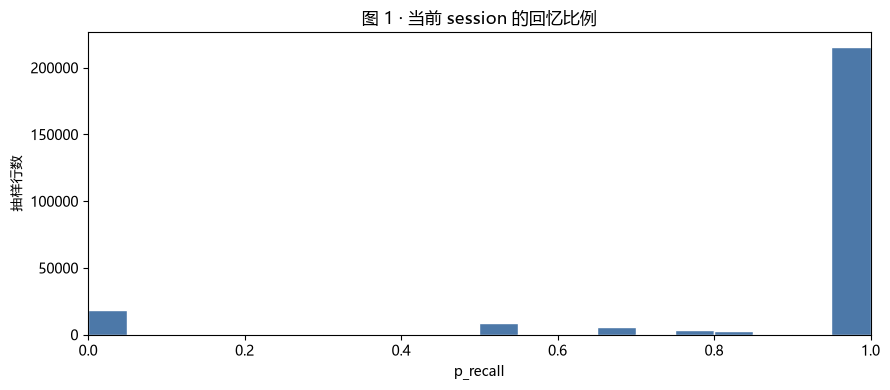

全量 p_recall=0：906,340（7.05%）
全量 p_recall=1：10,782,942（83.89%）
全量中间值：1,164,944（9.06%）


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(eda["p_recall"], bins=np.linspace(0, 1, 21), color="#4C78A8", edgecolor="white")
ax.set(xlabel="p_recall", ylabel="抽样行数", title="图 1 · 当前 session 的回忆比例")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()
print(f"全量 p_recall=0：{full_p_zero:,}（{full_p_zero/full_row_count:.2%}）")
print(f"全量 p_recall=1：{full_p_one:,}（{full_p_one/full_row_count:.2%}）")
print(f"全量中间值：{full_row_count-full_p_zero-full_p_one:,}（{1-(full_p_zero+full_p_one)/full_row_count:.2%}）")

## 图 2 — 距上次练习的间隔

`delta` 原始单位为秒，图中换成天。横轴取对数以同时看短间隔和长尾；`delta=0` 无法放在对数轴上，另行计数。

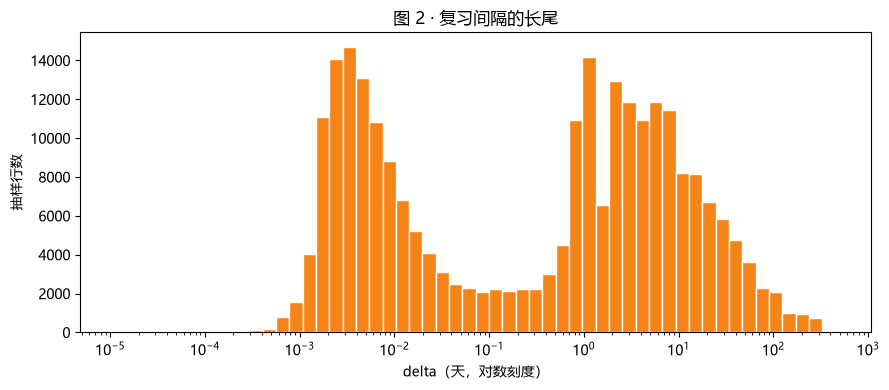

抽样中 delta=0： 0


0.00      0.000012
0.25      0.006157
0.50      0.893333
0.75      5.145463
0.90     19.907234
0.99    130.321304
1.00    452.799028
Name: delta_days, dtype: float64

In [8]:
positive_days = eda.loc[eda["delta_days"] > 0, "delta_days"]
fig, ax = plt.subplots(figsize=(9, 4))
if len(positive_days):
    log_bins = np.logspace(
        np.log10(positive_days.min()), np.log10(positive_days.max()), 55
    )
    ax.hist(positive_days, bins=log_bins, color="#F58518", edgecolor="white")
    ax.set_xscale("log")
ax.set(xlabel="delta（天，对数刻度）", ylabel="抽样行数", title="图 2 · 复习间隔的长尾")
plt.tight_layout()
plt.show()
print("抽样中 delta=0：", int(eda["delta"].eq(0).sum()))
display(eda["delta_days"].quantile([0, .25, .5, .75, .9, .99, 1]).rename("delta_days"))

## 图 3 — 历史见词与答对次数

两个历史计数都来自当前 session 之前。横轴显示“次数 + 1”，这样零次也能出现在对数坐标中。

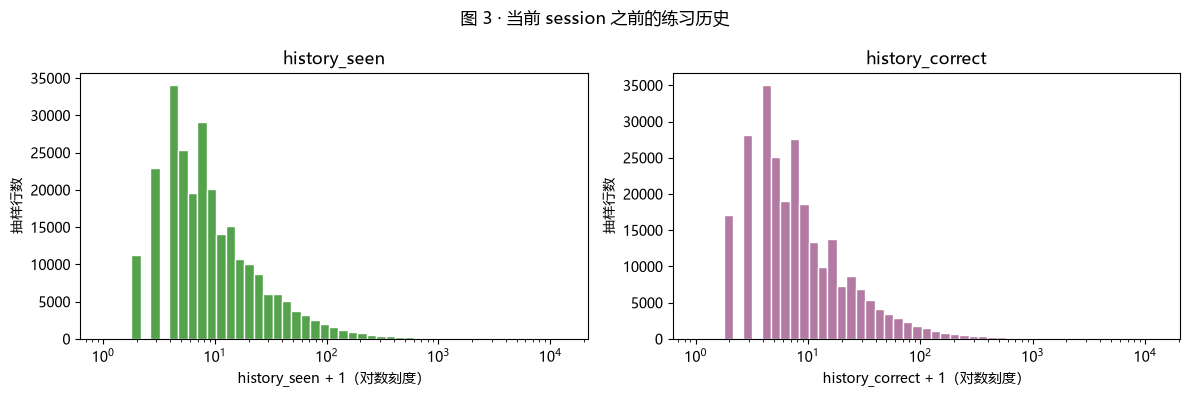

,history_seen,history_correct
0.00,1.0,1.0
0.50,6.0,6.0
0.90,36.0,32.0
0.99,239.0,208.0
1.00,13394.0,12772.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, field, color in zip(
    axes, ["history_seen", "history_correct"], ["#54A24B", "#B279A2"]
):
    values = eda[field].to_numpy() + 1
    bins = np.logspace(0, np.log10(values.max() + 1), 50)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set(xlabel=f"{field} + 1（对数刻度）", ylabel="抽样行数", title=field)
plt.suptitle("图 3 · 当前 session 之前的练习历史")
plt.tight_layout()
plt.show()
display(eda[["history_seen", "history_correct"]].quantile([0, .5, .9, .99, 1]))

## 图 4 — 不同时间间隔下的平均回忆比例

上图是每组平均比例，下图是该组的**抽样行数**。分组边界均以天计；大间隔组的均值需结合样本数和长尾看。

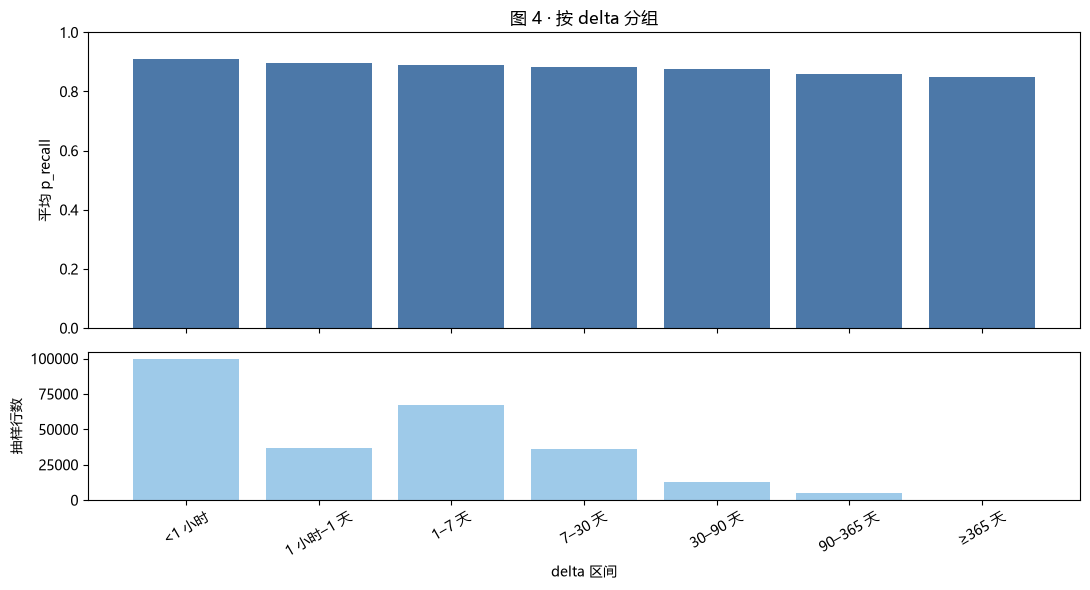

,mean_recall,n
delta_bin,,
<1 小时,0.908760,99465
1 小时–1 天,0.896552,36633
1–7 天,0.890132,67388
7–30 天,0.882926,36081
30–90 天,0.874673,12730
90–365 天,0.860563,4766
≥365 天,0.848485,22


In [10]:
delta_edges = [-np.inf, 1/24, 1, 7, 30, 90, 365, np.inf]
delta_labels = ["<1 小时", "1 小时–1 天", "1–7 天", "7–30 天",
                "30–90 天", "90–365 天", "≥365 天"]
eda["delta_bin"] = pd.cut(
    eda["delta_days"], bins=delta_edges, labels=delta_labels, right=False
)
delta_summary = eda.groupby("delta_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(delta_labels, delta_summary["mean_recall"], color="#4C78A8")
axes[0].set(ylabel="平均 p_recall", ylim=(0, 1), title="图 4 · 按 delta 分组")
axes[1].bar(delta_labels, delta_summary["n"], color="#9ECAE9")
axes[1].set(ylabel="抽样行数", xlabel="delta 区间")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(delta_summary)

## 图 5 — 不同历史次数下的平均回忆比例

同样同时显示均值和每组抽样行数；这里按当前 session **之前**的 `history_seen` 分组。

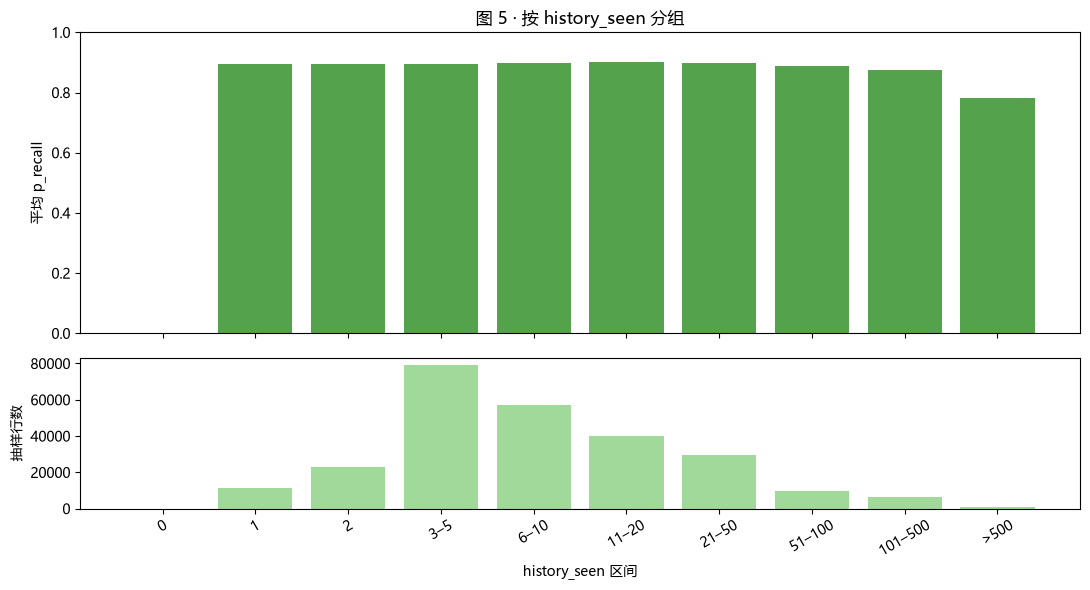

,mean_recall,n
seen_bin,,
0,NaN,0
1,0.895135,11289
2,0.896172,22969
3–5,0.894886,78981
6–10,0.897797,57002
11–20,0.901240,40040
21–50,0.899123,29407
51–100,0.887947,9800
101–500,0.875830,6577


In [11]:
seen_edges = [-1, 0, 1, 2, 5, 10, 20, 50, 100, 500, np.inf]
seen_labels = ["0", "1", "2", "3–5", "6–10", "11–20",
               "21–50", "51–100", "101–500", ">500"]
eda["seen_bin"] = pd.cut(
    eda["history_seen"], bins=seen_edges, labels=seen_labels
)
seen_summary = eda.groupby("seen_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(seen_labels, seen_summary["mean_recall"], color="#54A24B")
axes[0].set(ylabel="平均 p_recall", ylim=(0, 1), title="图 5 · 按 history_seen 分组")
axes[1].bar(seen_labels, seen_summary["n"], color="#A1D99B")
axes[1].set(ylabel="抽样行数", xlabel="history_seen 区间")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(seen_summary)

## 图 6 — 语言组合

用户界面语言与学习语言一起定义语言组合。此图的行数和平均回忆比例是**全文件精确累计**，不是 2% 抽样估计。组间差异是描述性关联，不能直接解释为语言本身的因果作用。

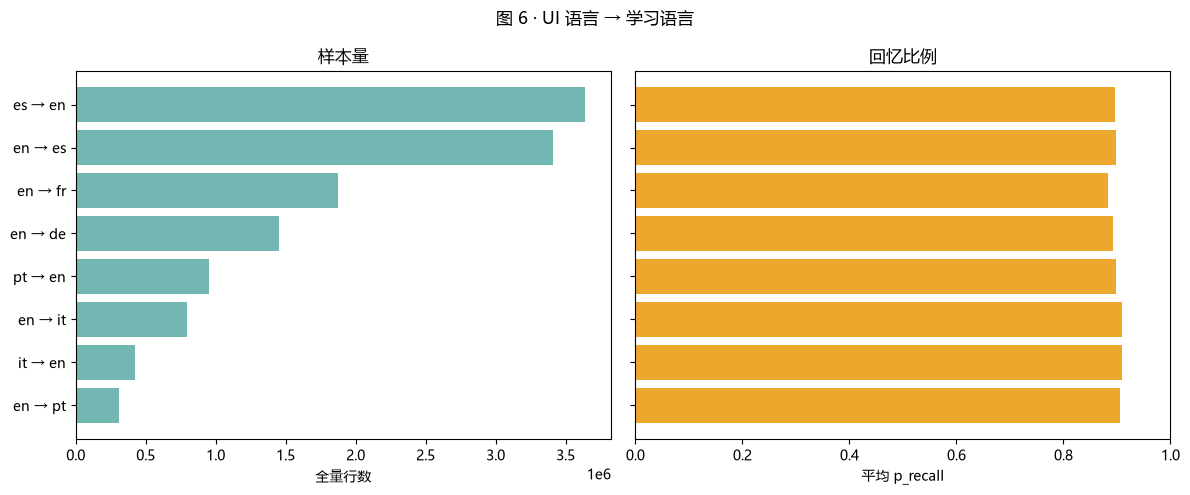

,pair,n,mean_recall
0,en → pt,311480,0.905512
1,it → en,424152,0.909596
2,en → it,793935,0.908592
3,pt → en,949460,0.898728
4,en → de,1452597,0.892786
5,en → fr,1873734,0.882750
6,en → es,3407689,0.898489
7,es → en,3641179,0.896289


In [12]:
pair_summary = pd.DataFrame([
    {
        "ui_language": ui, "learning_language": learning,
        "n": count, "mean_recall": pair_recall_sums[(ui, learning)] / count,
    }
    for (ui, learning), count in pair_counts.items()
]).sort_values("n", ascending=True).reset_index(drop=True)
pair_summary["pair"] = (
    pair_summary["ui_language"] + " → " + pair_summary["learning_language"]
)
positions = np.arange(len(pair_summary))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(positions, pair_summary["n"], color="#72B7B2")
axes[0].set(yticks=positions, yticklabels=pair_summary["pair"],
            xlabel="全量行数", title="样本量")
axes[1].barh(positions, pair_summary["mean_recall"], color="#ECA82C")
axes[1].set(xlabel="平均 p_recall", xlim=(0, 1), title="回忆比例")
fig.suptitle("图 6 · UI 语言 → 学习语言")
plt.tight_layout()
plt.show()
display(pair_summary[["pair", "n", "mean_recall"]])

## 图 7 — 用户与词项的观测次数

这两个频次分布由**全文件**累计：用户按 `user_id`，词项按 `learning_language:lexeme_id`。若只用 2% 样本来数，稀疏实体会被严重高估。横、纵轴都用对数刻度。全数据总观测次数少不等于预测时冷启动；真正的 train/test 冷启动分析要等数据切分后才能定义。

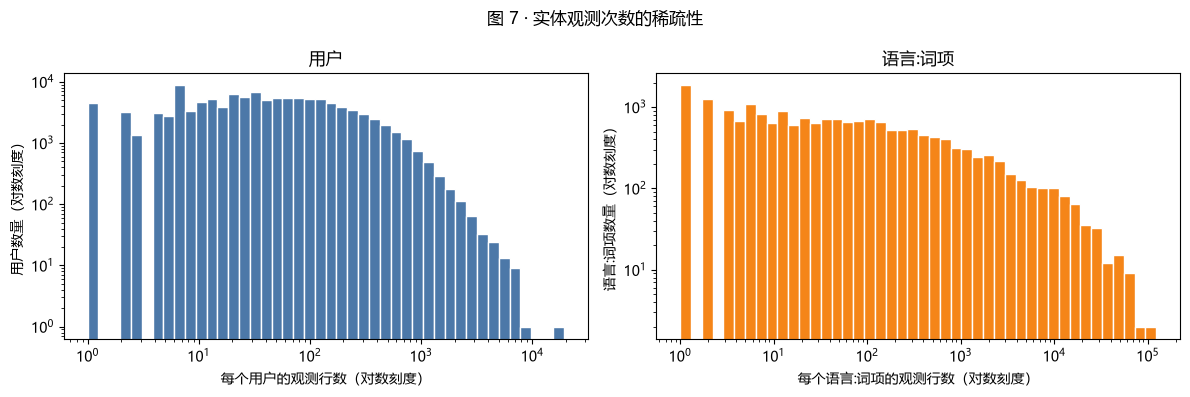

用户：115,222 个；≤5 行：11.43%
语言:词项：19,279 个；≤5 行：27.69%


,user_rows,lexeme_rows
0.00,1.00,1.00
0.50,34.00,26.00
0.90,280.00,963.00
0.99,1065.79,13757.08
1.00,19194.00,123099.00


In [13]:
user_frequency = np.fromiter(user_counts.values(), dtype=np.int64)
lexeme_frequency = np.fromiter(lexeme_counts.values(), dtype=np.int64)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, color, label in zip(
    axes,
    [user_frequency, lexeme_frequency],
    ["#4C78A8", "#F58518"],
    ["用户", "语言:词项"],
):
    bins = np.logspace(0, np.log10(values.max() + 1), 45)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(xlabel=f"每个{label}的观测行数（对数刻度）",
           ylabel=f"{label}数量（对数刻度）", title=label)
plt.suptitle("图 7 · 实体观测次数的稀疏性")
plt.tight_layout()
plt.show()
print(f"用户：{len(user_frequency):,} 个；≤5 行：{np.mean(user_frequency <= 5):.2%}")
print(f"语言:词项：{len(lexeme_frequency):,} 个；≤5 行：{np.mean(lexeme_frequency <= 5):.2%}")
display(pd.DataFrame({
    "user_rows": pd.Series(user_frequency).quantile([0, .5, .9, .99, 1]),
    "lexeme_rows": pd.Series(lexeme_frequency).quantile([0, .5, .9, .99, 1]),
}))

## 解释与后续检验

- 图 4 的 `delta`–`p_recall` 关系是**观察性关联**。Duolingo 会根据学习者表现调整复习时机（adaptive scheduling），不同间隔组的学习者和词项并非随机分配，不能把组均值差直接解释成遗忘的因果效应。
- 文件顺序不能直接当作严格时间顺序；CP2 发现相邻时间戳有逆序。CP4 的 Track A 会按文件顺序切分，另做真正时间切分时必须单独命名和评估。
- 同一用户可能同时出现在 Train 和 Test。这对应已知用户后续表现的预测，不能自动推广为新用户泛化。只有切分后统计用户交集，才能确定重叠程度。
- 平均值必须和分组行数一起看，特别是极长间隔、少见历史次数和不同语言组合。图 7 使用全量频次，但冷启动比例仍需在训练集定义“已见/未见”。

### 可检验的建模假设（留待 CP6–CP8）

1. **长间隔更难预测。** 在相同 Test 行上，HLR -lex 的 `delta > 30 天` 组 MAE 高于 `delta ≤ 1 天` 组；同时报告每组行数。
2. **历史少时误差更高。** 在相同 Test 行上，`history_seen ≤ 2` 组的 MAE 高于 `history_seen > 20` 组；用固定分组而非看完 Test 再改边界。
3. **词项特征对常见词更有帮助。** 用 Train 内出现次数定义常见/稀有词项，比较完整 HLR 与 HLR -lex 在相同 Test 行上的 MAE 差值；频次不能用 Test 计算。
4. **语言组合的误差不同。** 对固定模型按 `ui_language → learning_language` 报告 Test MAE 和样本数，检查整体 MAE 是否掩盖组间差异。

这些假设是后续评估计划，不是从本节图形已证明的结论。

## 七张图的解释

1. **回忆比例（图 1）**：`p_recall=1` 占全量 **83.89%**，`=0` 占 **7.05%**，中间值占 **9.06%**。目标高度集中在 1，后续不能只看整体平均误差，还要看模型在答错和部分答对的记录上表现如何。

2. **复习间隔（图 2）**：分布有短至几分钟和约一天至数天的两片集中区域，并有很长的尾巴。抽样中位数约 **21.4 小时**，99% 分位约 **130 天**。因此图用了对数横轴；普通线性横轴会把短间隔挤在一起。

3. **历史练习次数（图 3）**：多数记录的历史不长：`history_seen` 中位数 **6**，90% 分位 **36**；少数记录却达到上万次。这说明计数有长尾，后续特征设计需要关注极大值。两列的中位数都为 6，**不代表**每一行此前都答对了。

4. **间隔与回忆率（图 4）**：平均 `p_recall` 随间隔增加，从 `<1 小时` 的 **0.909** 降到 `≥365 天` 的 **0.848**。这是观察到的关联；最右组只有 **22 条抽样记录**，而且复习时间会受学习表现影响，不能把下降幅度直接解释为纯粹的遗忘效应。

5. **历史次数与回忆率（图 5）**：`history_seen` 为 1–50 时，组均值大致在 **0.89–0.90**；`>500` 时降至 **0.780**（抽样 **1,020 行**）。这**不能说明练得越多越差**：难词或困难用户可能本来就需要更多次练习。`0` 组没有记录，所以其均值显示 `NaN`。

6. **语言组合（图 6）**：不同组合的全量样本数差很多，从约 **31 万**到 **364 万**；平均回忆率约 **0.883–0.910**。后续应报告各语言组的误差及样本数，但这些均值不能直接当作语言难度排名。

7. **用户与词项频次（图 7）**：观测次数很不均衡。用户中位数为 **34 行**，词项中位数为 **26 行**；**11.43%** 的用户、**27.69%** 的词项只有不超过 5 行。这提示后续要检查稀疏实体的预测误差；真正的“新用户／新词项”仍须在划分 Train/Test 后定义。

整体上，最突出的特征是：**回忆率集中在 1、时间与历史次数都有长尾、不同实体和语言组的样本量不均衡**。这些图给出了后续建模和分组评估的方向，还不是模型效果或因果结论。

# CP4 — 固定文件顺序切分

本节使用**原始 gzip CSV 的零基数据行号**（不含表头），并保持文件顺序。Track A 按论文和公开代码取前 90% Train、后 10% Test；Track B 取前 72% Train、接下来的 18% Validation、最后 10% Test。两个 Track 使用同一批原始行和同一个 Test 区间。`p_recall` 的分布仅用于切分审计，不用于选模型或调参。

[原论文 §4.1](https://aclanthology.org/P16-1174.pdf) 的作者曾用最初约 100 万行试过训练参数；这里的“Track A 不调参”指复现时固定论文参数，不用保留的 Test 再选值。Track A 的行序切分与[公开代码](https://github.com/duolingo/halflife-regression/blob/master/experiment.py)一致。Track B 只用 Validation 选方案，之后在 Train+Validation 重新训练，最终 Test 只评估一次。

In [14]:
import hashlib
import json

audit_path = data_path.parents[2] / "reports" / "data_quality.json"
if not audit_path.is_file():
    raise FileNotFoundError("CP4 需要 CP2 的全量 reports/data_quality.json。")
audit = json.loads(audit_path.read_text(encoding="utf-8"))
if audit["scope"] != "full_file":
    raise ValueError("CP2 报告不是全文件审计。")

digest = hashlib.sha256()
with data_path.open("rb") as source:
    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
        digest.update(block)
source_sha256 = digest.hexdigest()
if source_sha256 != audit["input_sha256"]:
    raise ValueError("原始文件与 CP2 报告的 SHA-256 不一致，停止切分。")
if audit["track_b_excluded_rows"] != 0:
    raise ValueError("CP2 有排除行；需先定义过滤后行号，再固定 Track B 切分。")

n_rows = int(audit["total_rows"])
train_end_b = int(0.72 * n_rows)
test_start = int(0.90 * n_rows)
split_ranges = {
    "A": {"train": (0, test_start), "test": (test_start, n_rows)},
    "B": {
        "train": (0, train_end_b),
        "validation": (train_end_b, test_start),
        "test": (test_start, n_rows),
    },
}
TRAIN_SHUFFLE_SEED = 42  # 供后续训练使用；切分本身不涉及随机数

def split_for_row(row_index: int, track: str = "B") -> str:
    """Return the fixed split for a zero-based raw CSV data-row index."""
    if not 0 <= row_index < n_rows:
        raise IndexError(f"行号超出 0..{n_rows-1}: {row_index}")
    if track not in split_ranges:
        raise ValueError("track 必须为 'A' 或 'B'")
    return next(
        name for name, (start, stop) in split_ranges[track].items()
        if start <= row_index < stop
    )

split_manifest = {
    "file_name": data_path.name,
    "source_sha256": source_sha256,
    "row_count": n_rows,
    "index_base": 0,
    "interval_convention": "[start, stop)",
    "order": "raw_csv_file_order",
    "train_shuffle_seed_for_later": TRAIN_SHUFFLE_SEED,
    "track_a": split_ranges["A"],
    "track_b": split_ranges["B"],
}
print(json.dumps(split_manifest, ensure_ascii=False, indent=2))
display(pd.DataFrame([
    {"track": track, "split": name, "start": start, "stop_exclusive": stop,
     "last_inclusive": stop - 1, "rows": stop - start}
    for track, ranges in split_ranges.items()
    for name, (start, stop) in ranges.items()
]))

{
  "file_name": "settles.acl16.learning_traces.13m.csv.gz",
  "source_sha256": "26cf9b33f2e9b2e8aa9a8f262a017b30699ca2f625c56a12ce699d4ea7076873",
  "row_count": 12854226,
  "index_base": 0,
  "interval_convention": "[start, stop)",
  "order": "raw_csv_file_order",
  "train_shuffle_seed_for_later": 42,
  "track_a": {
    "train": [
      0,
      11568803
    ],
    "test": [
      11568803,
      12854226
    ]
  },
  "track_b": {
    "train": [
      0,
      9255042
    ],
    "validation": [
      9255042,
      11568803
    ],
    "test": [
      11568803,
      12854226
    ]
  }
}


,track,split,start,stop_exclusive,last_inclusive,rows
0,A,train,0,11568803,11568802,11568803
1,A,test,11568803,12854226,12854225,1285423
2,B,train,0,9255042,9255041,9255042
3,B,validation,9255042,11568803,11568802,2313761
4,B,test,11568803,12854226,12854225,1285423


## 全文件切分审计

以下只顺序读取压缩 CSV，一次处理一行，不把约 1,285 万行全部载入内存。记录每个集合的行数、`p_recall` 均值及端点比例、UTC 时间范围和文件内部的相邻时间逆序次数。Track A 的 Train 统计由 Track B 的 Train + Validation 合并得到；Test 区间完全相同。

In [ ]:
import csv
import gzip

def empty_split_stats():
    return {
        "rows": 0, "p_sum": 0.0, "p_zero": 0, "p_one": 0,
        "min_ts": None, "max_ts": None, "first_ts": None, "last_ts": None,
        "timestamp_backwards": 0,
    }

b_stats = {name: empty_split_stats() for name in split_ranges["B"]}
b_users = {name: set() for name in split_ranges["B"]}
b_lexemes = {name: set() for name in split_ranges["B"]}
global_backwards = 0
previous_ts = None

with gzip.open(data_path, "rt", encoding="utf-8", newline="") as source:
    reader = csv.DictReader(source)
    if reader.fieldnames != expected_columns:
        raise ValueError("原始 CSV 表头已变化。")
    for row_index, row in enumerate(reader):
        name = split_for_row(row_index, "B")
        state = b_stats[name]
        p = float(row["p_recall"])
        ts = int(row["timestamp"])
        if previous_ts is not None and ts < previous_ts:
            global_backwards += 1
        previous_ts = ts

        if state["first_ts"] is None:
            state["first_ts"] = ts
        if state["last_ts"] is not None and ts < state["last_ts"]:
            state["timestamp_backwards"] += 1
        state["last_ts"] = ts
        state["min_ts"] = ts if state["min_ts"] is None else min(state["min_ts"], ts)
        state["max_ts"] = ts if state["max_ts"] is None else max(state["max_ts"], ts)
        state["rows"] += 1
        state["p_sum"] += p
        state["p_zero"] += (p == 0)
        state["p_one"] += (p == 1)
        b_users[name].add(row["user_id"])
        b_lexemes[name].add((row["learning_language"], row["lexeme_string"]))

assert sum(state["rows"] for state in b_stats.values()) == n_rows
assert b_stats["train"]["rows"] == train_end_b
assert b_stats["validation"]["rows"] == test_start - train_end_b
assert b_stats["test"]["rows"] == n_rows - test_start
assert global_backwards == audit["special_counts"]["timestamp_backwards_adjacent"]

def merge_split_stats(left, right):
    return {
        "rows": left["rows"] + right["rows"],
        "p_sum": left["p_sum"] + right["p_sum"],
        "p_zero": left["p_zero"] + right["p_zero"],
        "p_one": left["p_one"] + right["p_one"],
        "min_ts": min(left["min_ts"], right["min_ts"]),
        "max_ts": max(left["max_ts"], right["max_ts"]),
        "timestamp_backwards": (
            left["timestamp_backwards"] + right["timestamp_backwards"]
            + int(right["first_ts"] < left["last_ts"])
        ),
    }

a_stats = {
    "train": merge_split_stats(b_stats["train"], b_stats["validation"]),
    "test": b_stats["test"],
}

def split_summary_row(track, name, state):
    count = state["rows"]
    return {
        "track": track, "split": name, "rows": count,
        "mean_p_recall": state["p_sum"] / count,
        "p_recall_0_pct": 100 * state["p_zero"] / count,
        "p_recall_1_pct": 100 * state["p_one"] / count,
        "timestamp_min_utc": pd.to_datetime(state["min_ts"], unit="s", utc=True),
        "timestamp_max_utc": pd.to_datetime(state["max_ts"], unit="s", utc=True),
        "adjacent_time_reversals": state["timestamp_backwards"],
    }

split_summary = pd.DataFrame(
    [split_summary_row("A", name, state) for name, state in a_stats.items()]
    + [split_summary_row("B", name, state) for name, state in b_stats.items()]
)
display(split_summary)
print(f"全文件相邻时间逆序：{global_backwards:,} 次")
print("A Train 最大时间 =", split_summary.loc[0, "timestamp_max_utc"])
print("A/B Test 最小时间 =", split_summary.loc[1, "timestamp_min_utc"])

## 行级边界与实体重叠

半开区间 `[start, stop)` 使每条**原始行**恰好属于各 Track 的一个集合。用户或词项在多个集合出现不等于行泄漏：本协议评估的是包含已见用户、已见词项的后续记录，并非专门的新用户泛化。后续建立词项词表或任何学习得到的统计量时，必须只在 Train 拟合；Validation/Test 的新词项按未知特征处理。

In [ ]:
boundary_indices = [
    0, train_end_b - 1, train_end_b,
    test_start - 1, test_start, n_rows - 1,
]
boundary_check = pd.DataFrame([
    {
        "raw_row_index": index,
        "track_a": split_for_row(index, "A"),
        "track_b": split_for_row(index, "B"),
    }
    for index in boundary_indices
])
display(boundary_check)
assert split_ranges["A"]["test"] == split_ranges["B"]["test"]
assert split_ranges["B"]["train"][1] == split_ranges["B"]["validation"][0]
assert split_ranges["B"]["validation"][1] == split_ranges["B"]["test"][0]
assert split_ranges["B"]["test"][1] == n_rows
assert sum(stop - start for start, stop in split_ranges["B"].values()) == n_rows
assert a_stats["train"]["rows"] + a_stats["test"]["rows"] == n_rows

train_val_users = b_users["train"] | b_users["validation"]
train_val_lexemes = b_lexemes["train"] | b_lexemes["validation"]
print(f"A Train/Test 共同用户：{len(train_val_users & b_users['test']):,}")
print(f"B Train/Validation 共同用户：{len(b_users['train'] & b_users['validation']):,}")
print(f"B Train/Test 共同用户：{len(b_users['train'] & b_users['test']):,}")
print(f"B Validation 中 Train 未见词项：{len(b_lexemes['validation'] - b_lexemes['train']):,}")
print(f"B Test 中 Train+Validation 未见词项：{len(b_lexemes['test'] - train_val_lexemes):,}")

## CP4 固定协议

- **Track A（论文对照）**：文件顺序前 90% Train / 后 10% Test；采用论文确定的超参数，不根据 Test 结果重新调参。训练内部的 shuffle 使用固定 seed 42，供后续实现复用。
- **Track B（开发）**：文件顺序 72% Train / 18% Validation / 10% Test。只在 Validation 选超参数；确定方案后用 Train+Validation 从头重训，最终 Test 仅评估一次。
- 两套协议共用同一个原始文件 SHA-256 和最后 10% Test 行号。切分、字段选择和各模型的评估都必须复用上面的 `split_for_row()` 与 `split_ranges`；不能用 CP1 的前 100,000 行预览代替全文件。
- `timestamp` 只用于审计，**没有参与本次切分**。若以后需要单独的严格未来预测实验，应预先指定时间截止点和同一秒记录的归属，并将结果标为另一个协议。
- 当前 CP2 的 Track B 有效性规则排除 0 行，81 条完整重复行按此前决定保留，因此两个 Track 的行号都直接对应原始 CSV。若原始文件或清洗政策变化，前面的哈希和行数检查会要求重新固定切分。
- 本次全文件校验得到：A Train 11,568,803 行、Test 1,285,423 行；B Train 9,255,042 行、Validation 2,313,761 行、Test 1,285,423 行。A Train/Test 有 17,692 名共同用户；B Validation 有 656 个 Train 未见词项，B Test 有 270 个 Train+Validation 未见词项。

# CP5 — HLR 特征工程

沿用 CP4 的原始文件顺序和 Track A / B 切分。按 [公开实现 read_data()](https://github.com/duolingo/halflife-regression/blob/master/experiment.py) 构建 HLR -lex 与完整 HLR 的特征；本节不训练模型。81 条完整重复行及已发现的历史计数倒退行暂时保留，两个 Track 均使用原始行值。

In [15]:
BASE_FEATURE_NAMES = ["sqrt(1+history_correct)", "sqrt(1+history_seen-history_correct)", "bias"]
HLR_MIN_H, HLR_MAX_H = 15.0 / 1440.0, 274.0
HLR_MIN_P, HLR_MAX_P = 0.0001, 0.9999

def hlr_lexless_features(frame):
    correct = frame["history_correct"].to_numpy(dtype=np.float64)
    wrong = frame["history_seen"].to_numpy(dtype=np.float64) - correct
    if np.any(correct < 0) or np.any(wrong < 0):
        raise ValueError("history_seen >= history_correct >= 0 必须在每一行成立")
    return np.column_stack((np.sqrt(1.0 + correct), np.sqrt(1.0 + wrong),
                            np.ones(len(frame), dtype=np.float64)))

def observed_hlr_targets(p_recall, delta_seconds):
    p = np.clip(np.asarray(p_recall, dtype=np.float64), HLR_MIN_P, HLR_MAX_P)
    days = np.asarray(delta_seconds, dtype=np.float64) / 86400.0
    h = np.clip(-days / np.log2(p), HLR_MIN_H, HLR_MAX_H)
    return p, days, h

def lexeme_keys(frame):
    return frame["learning_language"].astype(str).str.cat(
        frame["lexeme_string"].astype(str), sep=":"
    )

def hlr_feature_batch(frame, vocabulary):
    # 一个词项列号代替宽大的 dense one-hot；-1 表示该词项不在训练词表中。
    columns = lexeme_keys(frame).map(vocabulary).fillna(-1).to_numpy(dtype=np.int32)
    p, days, h = observed_hlr_targets(frame["p_recall"], frame["delta"])
    return {"base": hlr_lexless_features(frame), "lexeme_column": columns,
            "p_target": p, "delta_days": days, "h_observed": h}

def active_hlr_features(row, vocabulary):
    correct = float(row["history_correct"])
    wrong = float(row["history_seen"]) - correct
    if correct < 0 or wrong < 0:
        raise ValueError("本行历史计数无效")
    result = {0: np.sqrt(1.0 + correct), 1: np.sqrt(1.0 + wrong), 2: 1.0}
    key = f'{row["learning_language"]}:{row["lexeme_string"]}'
    column = vocabulary.get(key)
    if column is not None:
        result[column] = 1.0
    return result

## 按训练段建立词表

只扫描 learning_language 和 lexeme_string 两列，每批 25 万行。Track B 模型选择用前 72% 建词表；Track A 和 Track B 最终重训用前 90%。Validation / Test 中未见词项的 one-hot 全为 0，并统计对应行数。

In [16]:
vocab_b_train, vocab_a_train = {}, {}
b_validation_unknown = test_unknown = rows_scanned = 0

for chunk in pd.read_csv(
    data_path, compression="gzip", usecols=["learning_language", "lexeme_string"],
    dtype={"learning_language": "string", "lexeme_string": "string"}, chunksize=250_000,
):
    start, stop = rows_scanned, rows_scanned + len(chunk)
    keys = lexeme_keys(chunk)
    train_stop = min(stop, train_end_b)
    if start < train_stop:
        for key in pd.unique(keys.iloc[:train_stop - start]):
            vocab_b_train.setdefault(key, 3 + len(vocab_b_train))
            vocab_a_train.setdefault(key, 3 + len(vocab_a_train))
    val_start, val_stop = max(start, train_end_b), min(stop, test_start)
    if val_start < val_stop:
        val_keys = keys.iloc[val_start - start:val_stop - start]
        b_validation_unknown += int((~val_keys.isin(vocab_b_train)).sum())
        for key in pd.unique(val_keys):
            vocab_a_train.setdefault(key, 3 + len(vocab_a_train))
    test_begin = max(start, test_start)
    if test_begin < stop:
        test_unknown += int((~keys.iloc[test_begin - start:].isin(vocab_a_train)).sum())
    rows_scanned = stop

assert rows_scanned == n_rows
assert all(vocab_a_train[key] == col for key, col in vocab_b_train.items())
assert set(vocab_b_train.values()) == set(range(3, 3 + len(vocab_b_train)))
assert set(vocab_a_train.values()) == set(range(3, 3 + len(vocab_a_train)))
feature_names_b = BASE_FEATURE_NAMES + list(vocab_b_train)
feature_names_a = BASE_FEATURE_NAMES + list(vocab_a_train)
val_rows, test_rows = test_start - train_end_b, n_rows - test_start
feature_dimensions = pd.DataFrame([
    ["A 训练/测试", "前 90%", test_start, len(vocab_a_train), len(feature_names_a),
     test_unknown, test_rows, test_unknown / test_rows],
    ["B 模型选择", "前 72%", train_end_b, len(vocab_b_train), len(feature_names_b),
     b_validation_unknown, val_rows, b_validation_unknown / val_rows],
    ["B 重训/测试", "前 90%", test_start, len(vocab_a_train), len(feature_names_a),
     test_unknown, test_rows, test_unknown / test_rows],
], columns=["阶段", "词表来源", "训练行数", "词项数", "总维度",
            "未知词项行数", "评估行数", "未知词项比例"])
display(feature_dimensions)
print("前三个特征：", feature_names_a[:3])
print("前五个词项特征：", feature_names_a[3:8])

,阶段,词表来源,训练行数,词项数,总维度,未知词项行数,评估行数,未知词项比例
0,A 训练/测试,前 90%,11568803,19009,19012,346,1285423,0.000269
1,B 模型选择,前 72%,9255042,18353,18356,1150,2313761,0.000497
2,B 重训/测试,前 90%,11568803,19009,19012,346,1285423,0.000269


前三个特征： ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
前五个词项特征： ['de:lernt/lernen<vblex><pri><p3><sg>', 'de:die/die<det><def><f><sg><nom>', 'de:mann/mann<n><m><sg><nom>', 'de:frau/frau<n><f><sg><nom>', 'de:das/das<det><def><nt><sg><nom>']


## 数值与防泄漏检查

完整 HLR 的每行只含三个数值特征及至多一个活跃词项列。p_recall 与从它推导的 h_observed 仅作训练目标；delta_days 是遗忘曲线的时间参数，不是可学习的特征列。

In [17]:
zero = pd.DataFrame({"history_seen": [0], "history_correct": [0]})
ten_eight = pd.DataFrame({"history_seen": [10], "history_correct": [8]})
np.testing.assert_allclose(hlr_lexless_features(zero), [[1.0, 1.0, 1.0]])
np.testing.assert_allclose(hlr_lexless_features(ten_eight), [[3.0, np.sqrt(3.0), 1.0]])
assert len(BASE_FEATURE_NAMES) == 3
assert not {"p_recall", "session_correct", "session_seen", "delta"}.intersection(BASE_FEATURE_NAMES)

probe = preview.head(3).copy()
changed = probe.copy()
changed["p_recall"], changed["session_seen"], changed["session_correct"] = 0.0, 999, 0
np.testing.assert_array_equal(hlr_lexless_features(probe), hlr_lexless_features(changed))
np.testing.assert_array_equal(
    hlr_feature_batch(probe, vocab_b_train)["lexeme_column"],
    hlr_feature_batch(changed, vocab_b_train)["lexeme_column"])
p, days, h = observed_hlr_targets([0.0, 1.0], [86400, 86400])
np.testing.assert_allclose(days, [1.0, 1.0])
np.testing.assert_allclose(p, [0.0001, 0.9999])
assert np.isfinite(h).all() and np.all((HLR_MIN_H <= h) & (h <= HLR_MAX_H))

unknown_row = probe.iloc[0].to_dict()
unknown_row["lexeme_string"] = "__CP5_never_seen_lexeme__"
assert set(active_hlr_features(unknown_row, vocab_b_train)) == {0, 1, 2}
first = probe.iloc[0]
active = active_hlr_features(first, vocab_b_train)
np.testing.assert_allclose([active[i] for i in range(3)], hlr_lexless_features(probe.iloc[:1])[0])
assert active[vocab_b_train[f'{first["learning_language"]}:{first["lexeme_string"]}']] == 1.0

sample = hlr_feature_batch(probe, vocab_b_train)
display(pd.DataFrame({
    "raw_row_index": probe.index,
    BASE_FEATURE_NAMES[0]: sample["base"][:, 0],
    BASE_FEATURE_NAMES[1]: sample["base"][:, 1],
    "bias": sample["base"][:, 2],
    "lexeme_column": sample["lexeme_column"],
    "delta_days": sample["delta_days"],
    "p_target_clipped": sample["p_target"],
    "h_observed_days": sample["h_observed"],
}))
print("CP5 断言通过；样例数值符合公开 read_data() 的公式。")

,raw_row_index,sqrt(1+history_correct),sqrt(1+history_seen-history_correct),bias,lexeme_column,delta_days,p_target_clipped,h_observed_days
0,0,2.236068,1.732051,1.0,3,320.018924,0.9999,274.0
1,1,2.236068,1.000000,1.0,4,320.018924,0.5000,274.0
2,2,2.236068,1.414214,1.0,5,320.018924,0.9999,274.0


CP5 断言通过；样例数值符合公开 read_data() 的公式。


## CP5 使用约定

- feature_names_b / vocab_b_train 对应 B Train → Validation；feature_names_a / vocab_a_train 对应 A Train → Test 和 B Train+Validation 重训 → Test。
- hlr_feature_batch(frame, vocabulary) 返回分块表示。base 和 lexeme_column 是预测输入；p_target、delta_days、h_observed 分别是目标或时间参数。
- 两个 Track 都保留当前原始数据异常。后续如研究异常影响，另设独立实验协议。

# CP6 — 训练 HLR

本节对照 [官方 experiment.py 的 predict / train_update / train](https://github.com/duolingo/halflife-regression/blob/master/experiment.py) 实现一次随机顺序的在线训练。Track A 固定官方默认参数；Track B 先比较 Validation 上的 HLR -lex 与完整 HLR，再按选中的模型用前 90% 从头训练。CP5 的原始行和词表政策保持不变。

In [ ]:
import math
import os
import time

CP6_ALPHA = 0.01
CP6_L2 = 0.1
CP6_LRATE = 0.001
CP6_SEED = 42
CP6_LOG_MIN_H = math.log2(HLR_MIN_H)
CP6_LOG_MAX_H = math.log2(HLR_MAX_H)

def predict_half_life(base, weights, lexeme_columns=None):
    base = np.asarray(base, dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)
    if base.ndim != 2 or base.shape[1] != 3 or len(weights) < 3:
        raise ValueError("base 必须是 n×3，weights 至少有 3 个参数")
    scores = base @ weights[:3]
    if lexeme_columns is not None and len(weights) > 3:
        columns = np.asarray(lexeme_columns, dtype=np.int64)
        known = (columns >= 3) & (columns < len(weights))
        scores[known] += weights[columns[known]]
    return np.exp2(np.clip(scores, CP6_LOG_MIN_H, CP6_LOG_MAX_H))

def predict_recall(delta_days, half_life_days):
    days = np.asarray(delta_days, dtype=np.float64)
    half_life = np.asarray(half_life_days, dtype=np.float64)
    return np.clip(np.exp2(-days / half_life), HLR_MIN_P, HLR_MAX_P)

def hlr_loss(p_true, h_true, p_pred, h_pred, weights, alpha=CP6_ALPHA, l2=CP6_L2):
    p_sq = np.square(np.asarray(p_true) - np.asarray(p_pred)).sum()
    h_sq = np.square(np.asarray(h_true) - np.asarray(h_pred)).sum()
    penalty = np.square(np.asarray(weights)).sum()
    return float(p_sq + alpha * h_sq + l2 * penalty)

上面两次裁剪与官方一致：预测半衰期限制在 15 分钟到 274 天，预测正确率限制在 0.0001 到 0.9999。Loss 用观察正确率、观察半衰期及 L2 项计算；delta_days 只进入遗忘曲线。官方更新代码对裁剪边界直接使用裁剪后的预测值，在边界处不单独计算裁剪函数的导数。

In [ ]:
CP6_DTYPE = np.dtype([
    ("x_correct", "<f8"), ("x_wrong", "<f8"), ("lexeme_column", "<i4"),
    ("p_target", "<f8"), ("delta_days", "<f8"), ("h_observed", "<f8"),
])

def cp6_predict_records(records, weights):
    base = np.column_stack((
        records["x_correct"], records["x_wrong"],
        np.ones(len(records), dtype=np.float64),
    ))
    half_life = predict_half_life(base, weights, records["lexeme_column"])
    recall = predict_recall(records["delta_days"], half_life)
    return recall, half_life

def cp6_evaluate_records(records, weights):
    p_pred, h_pred = cp6_predict_records(records, weights)
    p_err = np.asarray(records["p_target"]) - p_pred
    h_err = np.asarray(records["h_observed"]) - h_pred
    p_sq = float(np.dot(p_err, p_err))
    h_sq = float(np.dot(h_err, h_err))
    count = len(records)
    if count == 0:
        raise ValueError("评估集不能为空")
    return {
        "rows": count,
        "mae_p": float(np.abs(p_err).mean()),
        "mae_h_days": float(np.abs(h_err).mean()),
        "p_sq": p_sq,
        "h_sq": h_sq,
        "loss": p_sq + CP6_ALPHA * h_sq + CP6_L2 * float(np.dot(weights, weights)),
    }

def cp6_evaluate_span(records, weights, start, stop, batch_size=200_000):
    if not 0 <= start < stop <= len(records):
        raise ValueError("评估区间超出缓存")
    total_p_abs = total_h_abs = total_p_sq = total_h_sq = 0.0
    for left in range(start, stop, batch_size):
        batch = records[left:min(left + batch_size, stop)]
        p_pred, h_pred = cp6_predict_records(batch, weights)
        p_err = np.asarray(batch["p_target"]) - p_pred
        h_err = np.asarray(batch["h_observed"]) - h_pred
        total_p_abs += float(np.abs(p_err).sum())
        total_h_abs += float(np.abs(h_err).sum())
        total_p_sq += float(np.dot(p_err, p_err))
        total_h_sq += float(np.dot(h_err, h_err))
    n = stop - start
    return {
        "rows": n,
        "mae_p": total_p_abs / n,
        "mae_h_days": total_h_abs / n,
        "p_sq": total_p_sq,
        "h_sq": total_h_sq,
        "loss": total_p_sq + CP6_ALPHA * total_h_sq
                + CP6_L2 * float(np.dot(weights, weights)),
    }

def cp6_train_epoch(records, train_stop, dimension, seed=CP6_SEED, log_every=1_000_000):
    """Official-style single-pass SGD. Only the deterministic shuffle differs from the unseeded script."""
    if not 0 < train_stop <= len(records) or dimension < 3:
        raise ValueError("训练范围或维度无效")
    weights = [0.0] * dimension
    feature_counts = [0] * dimension
    order = np.arange(train_stop, dtype=np.int32)
    np.random.default_rng(seed).shuffle(order)
    diagnostic_indices = np.linspace(
        0, train_stop - 1, min(100_000, train_stop), dtype=np.int32
    )
    diagnostic = records[diagnostic_indices]
    trace = [{"step": 0, **cp6_evaluate_records(diagnostic, np.asarray(weights))}]
    start_time = time.perf_counter()
    x_correct = records["x_correct"]
    x_wrong = records["x_wrong"]
    lexeme = records["lexeme_column"]
    p_target = records["p_target"]
    days = records["delta_days"]
    h_observed = records["h_observed"]
    use_lexeme = dimension > 3

    for step, row_index in enumerate(order, start=1):
        x0 = float(x_correct[row_index])
        x1 = float(x_wrong[row_index])
        column = int(lexeme[row_index])
        p = float(p_target[row_index])
        t = float(days[row_index])
        h_true = float(h_observed[row_index])
        score = weights[0] * x0 + weights[1] * x1 + weights[2]
        if use_lexeme and 3 <= column < dimension:
            score += weights[column]
        h_pred = math.exp2(min(max(score, CP6_LOG_MIN_H), CP6_LOG_MAX_H))
        p_pred = min(max(math.exp2(-t / h_pred), HLR_MIN_P), HLR_MAX_P)
        grad_p = 2.0 * (p_pred - p) * (math.log(2.0) ** 2) * p_pred * (t / h_pred)
        grad_h = 2.0 * (h_pred - h_true) * math.log(2.0) * h_pred
        active = ((0, x0), (1, x1), (2, 1.0))
        if use_lexeme and 3 <= column < dimension:
            active += ((column, 1.0),)
        for k, value in active:
            rate = CP6_LRATE / ((1.0 + p) * math.sqrt(1 + feature_counts[k]))
            weights[k] -= rate * grad_p * value
            weights[k] -= rate * CP6_ALPHA * grad_h * value
            weights[k] -= rate * CP6_L2 * weights[k]
            feature_counts[k] += 1
        if step % log_every == 0 or step == train_stop:
            metrics = cp6_evaluate_records(diagnostic, np.asarray(weights))
            trace.append({"step": step, **metrics})
            print(f"  {step:,}/{train_stop:,} 行；诊断 Loss={metrics['loss']:,.2f}；"
                  f"MAE(p)={metrics['mae_p']:.4f}；耗时 {time.perf_counter()-start_time:.1f}s")

    del order
    return np.asarray(weights), np.asarray(feature_counts), pd.DataFrame(trace)

训练函数只遍历一次打乱后的 Train 行。它逐特征执行官方的三个连续更新：正确率项、半衰期项、L2 收缩；学习率按该特征已出现次数衰减。固定 seed=42 使本复现可重跑，官方脚本的 random.shuffle 没有固定种子，所以数值不会逐位相同。每 100 万行在固定的训练样本上记录一次诊断 Loss；该样本不含 Validation 或 Test。

In [ ]:
# 合成数据：先验证预测边界，再验证公式导数和一轮训练。
synthetic = pd.DataFrame({
    "history_seen": np.arange(60) % 11 + 1,
    "history_correct": np.arange(60) % 11,
})
synthetic_base = hlr_lexless_features(synthetic)
synthetic_days = np.linspace(0.2, 2.0, len(synthetic))
synthetic_true_weights = np.array([0.45, -0.20, 0.25])
synthetic_h = predict_half_life(synthetic_base, synthetic_true_weights)
synthetic_p = predict_recall(synthetic_days, synthetic_h)
synthetic_records = np.zeros(len(synthetic), dtype=CP6_DTYPE)
synthetic_records["x_correct"] = synthetic_base[:, 0]
synthetic_records["x_wrong"] = synthetic_base[:, 1]
synthetic_records["lexeme_column"] = -1
synthetic_records["p_target"] = synthetic_p
synthetic_records["delta_days"] = synthetic_days
synthetic_records["h_observed"] = synthetic_h
assert np.isfinite(synthetic_p).all()
assert np.all((HLR_MIN_P <= synthetic_p) & (synthetic_p <= HLR_MAX_P))
assert np.all((HLR_MIN_H <= synthetic_h) & (synthetic_h <= HLR_MAX_H))
np.testing.assert_allclose(predict_half_life(synthetic_base[:2], np.zeros(3)), [1, 1])

# 在未触及 clip 边界时，用中心差分检查两个数据项的解析梯度。
x = synthetic_base[10:11]
t = synthetic_days[10:11]
p_true, h_true = synthetic_p[10:11], synthetic_h[10:11]
w_check = np.array([0.08, -0.03, 0.05])
h_check = predict_half_life(x, w_check)
p_check = predict_recall(t, h_check)
g_data = (2 * (p_check - p_true) * math.log(2)**2 * p_check * (t / h_check)
          + CP6_ALPHA * 2 * (h_check - h_true) * math.log(2) * h_check) * x[0]
numeric = []
for k in range(3):
    plus, minus = w_check.copy(), w_check.copy()
    plus[k] += 1e-6
    minus[k] -= 1e-6
    p_plus, h_plus = predict_recall(t, predict_half_life(x, plus)), predict_half_life(x, plus)
    p_minus, h_minus = predict_recall(t, predict_half_life(x, minus)), predict_half_life(x, minus)
    numeric.append((hlr_loss(p_true, h_true, p_plus, h_plus, plus, l2=0)
                    - hlr_loss(p_true, h_true, p_minus, h_minus, minus, l2=0)) / 2e-6)
np.testing.assert_allclose(g_data, numeric, rtol=1e-5, atol=1e-7)

toy_weights, toy_counts, toy_trace = cp6_train_epoch(
    synthetic_records, len(synthetic_records), 3, log_every=60
)
assert len(toy_weights) == 3
assert np.array_equal(toy_counts, [60, 60, 60])
assert toy_trace.iloc[-1]["loss"] < toy_trace.iloc[0]["loss"]
repeat_weights, repeat_counts, _ = cp6_train_epoch(
    synthetic_records, len(synthetic_records), 3, log_every=60
)
np.testing.assert_array_equal(toy_weights, repeat_weights)
np.testing.assert_array_equal(toy_counts, repeat_counts)
np.testing.assert_allclose(
    predict_half_life(synthetic_base[:1], [0, 0, 0, 0.5], [3]),
    [math.sqrt(2)],
)
np.testing.assert_allclose(
    predict_half_life(synthetic_base[:1], [0, 0, 0, 0.5], [-1]), [1.0]
)
display(toy_trace[["step", "loss", "mae_p"]])
print("合成数据检查通过。")

合成数据检查了预测区间、数据项的解析梯度、一轮训练后的 Loss 下降、固定种子的复现性，以及已知/未知词项的预测差异。有限差分不含 L2 项，因为官方逐特征收缩写法不是上面总 Loss 对 L2 项的完整导数；这里按官方更新代码实现。完整数据训练前先让这一段通过。

In [ ]:
# 单次顺序读取 gzip，建立紧凑的磁盘缓存；不保存宽大的 one-hot 矩阵。
cache_root = data_path.parent.parent / "interim"
cache_root.mkdir(parents=True, exist_ok=True)
cp6_cache_path = cache_root / "cp6_hlr_features_v1.dat"
cp6_manifest_path = cache_root / "cp6_hlr_features_v1.json"
cp6_vocab_hash = hashlib.sha256(
    "\n".join(vocab_a_train).encode("utf-8")
).hexdigest()
cp6_expected_manifest = {
    "source_sha256": source_sha256,
    "row_count": n_rows,
    "dtype": repr(CP6_DTYPE.descr),
    "a_vocabulary_sha256": cp6_vocab_hash,
    "a_vocabulary_size": len(vocab_a_train),
    "cache_version": 1,
}
cache_valid = False
if cp6_cache_path.is_file() and cp6_manifest_path.is_file():
    try:
        cache_valid = (
            json.loads(cp6_manifest_path.read_text(encoding="utf-8")) == cp6_expected_manifest
            and cp6_cache_path.stat().st_size == n_rows * CP6_DTYPE.itemsize
        )
    except (ValueError, OSError):
        cache_valid = False

if not cache_valid:
    partial_path = cp6_cache_path.with_suffix(".partial")
    cache_write = np.memmap(partial_path, dtype=CP6_DTYPE, mode="w+", shape=(n_rows,))
    cache_rows_written = 0
    for chunk in pd.read_csv(
        data_path, compression="gzip",
        usecols=["p_recall", "delta", "history_seen", "history_correct",
                 "learning_language", "lexeme_string"],
        chunksize=200_000,
    ):
        batch = hlr_feature_batch(chunk, vocab_a_train)
        stop = cache_rows_written + len(chunk)
        if stop > n_rows:
            raise ValueError("缓存行数超过 CP4 的原始文件行数")
        cache_write["x_correct"][cache_rows_written:stop] = batch["base"][:, 0]
        cache_write["x_wrong"][cache_rows_written:stop] = batch["base"][:, 1]
        cache_write["lexeme_column"][cache_rows_written:stop] = batch["lexeme_column"]
        cache_write["p_target"][cache_rows_written:stop] = batch["p_target"]
        cache_write["delta_days"][cache_rows_written:stop] = batch["delta_days"]
        cache_write["h_observed"][cache_rows_written:stop] = batch["h_observed"]
        cache_rows_written = stop
    assert cache_rows_written == n_rows
    cache_write.flush()
    del cache_write
    os.replace(partial_path, cp6_cache_path)
    cp6_manifest_path.write_text(
        json.dumps(cp6_expected_manifest, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("已建立 CP6 缓存。")
else:
    print("原始文件与词表指纹一致，复用 CP6 缓存。")

cp6_records = np.memmap(cp6_cache_path, dtype=CP6_DTYPE, mode="r", shape=(n_rows,))
assert cp6_records.shape == (n_rows,)
assert np.isfinite(cp6_records["h_observed"][:1000]).all()
print(f"缓存：{cp6_cache_path}，{cp6_cache_path.stat().st_size / 2**20:.1f} MiB")

缓存每行只存两个历史数值、一个词项列号、正确率目标、时间间隔和观察半衰期，约 539 MiB。缓存指纹绑定原始 gzip 和 Track A 训练词表；重新运行时可复用。Track B 的词表是 A 词表的前缀，因此它只接受列号小于 B 维度的词项；B Validation 中其余列视为未知。缓存写在 data/interim，Notebook 本身仍是唯一修改的源文件。

In [ ]:
# 先在两个训练范围各取前 10 万行，确认实际缓存的在线训练路径可运行。
cp6_smoke_rows = 100_000
cp6_smoke_a = cp6_records[:cp6_smoke_rows]
smoke_weights, smoke_counts, smoke_trace = cp6_train_epoch(
    cp6_smoke_a, cp6_smoke_rows, 3, log_every=cp6_smoke_rows
)
assert np.isfinite(smoke_weights).all()
assert np.array_equal(smoke_counts, [cp6_smoke_rows] * 3)
display(smoke_trace[["step", "loss", "mae_p"]])

这 10 万行只用于检查真实缓存和训练循环，不能当作正式分数。由于文件开头的时间间隔很特殊，一轮训练后的这段局部 Loss 不保证下降；正式训练下一段会重新初始化参数并使用整个 Train，展示覆盖整个训练范围的固定诊断样本曲线。

In [ ]:
# 固定默认参数：B 仅在 Validation 比较两种结构；A 不使用 Validation 或 Test 调参。
cp6_specs_b = {"HLR -lex": 3, "HLR": len(feature_names_b)}
cp6_specs_a = {"HLR -lex": 3, "HLR": len(feature_names_a)}
cp6_b_models, cp6_b_validation = {}, {}

for name, dimension in cp6_specs_b.items():
    print(f"Track B Train：{name}，{train_end_b:,} 行，{dimension:,} 参数")
    weights, counts, trace = cp6_train_epoch(cp6_records, train_end_b, dimension)
    assert len(weights) == dimension and np.isfinite(weights).all()
    assert trace.iloc[-1]["loss"] < trace.iloc[0]["loss"]
    cp6_b_models[name] = {"weights": weights, "counts": counts, "trace": trace}
    cp6_b_validation[name] = cp6_evaluate_span(
        cp6_records, weights, train_end_b, test_start
    )

cp6_selected = min(cp6_b_validation, key=lambda name: cp6_b_validation[name]["mae_p"])
display(pd.DataFrame([
    {"Track": "B Validation", "model": name, **metrics}
    for name, metrics in cp6_b_validation.items()
]).set_index(["Track", "model"])[["rows", "mae_p", "mae_h_days", "loss"]])
print("Track B 按 Validation MAE(p) 选中：", cp6_selected)

# 两种固定默认配置都在 A Train 上训练；B 的最终重训与相应 A 训练完全相同。
cp6_a_models, cp6_a_test = {}, {}
for name, dimension in cp6_specs_a.items():
    print(f"Track A Train / B 最终重训：{name}，{test_start:,} 行，{dimension:,} 参数")
    weights, counts, trace = cp6_train_epoch(cp6_records, test_start, dimension)
    assert len(weights) == dimension and np.isfinite(weights).all()
    assert trace.iloc[-1]["loss"] < trace.iloc[0]["loss"]
    cp6_a_models[name] = {"weights": weights, "counts": counts, "trace": trace}
    cp6_a_test[name] = cp6_evaluate_span(cp6_records, weights, test_start, n_rows)

display(pd.DataFrame([
    {"Track": "A Test", "model": name, **metrics}
    for name, metrics in cp6_a_test.items()
]).set_index(["Track", "model"])[["rows", "mae_p", "mae_h_days", "loss"]])
print("B 最终模型与相同配置的 A 模型使用同一前 90% 训练数据、词表、seed 和超参数；")
print(f"B 最终选中 {cp6_selected}，Test MAE(p)={cp6_a_test[cp6_selected]['mae_p']:.6f}")
display(pd.DataFrame({
    "feature": BASE_FEATURE_NAMES,
    "Track B 3 参数": cp6_b_models["HLR -lex"]["weights"],
    "Track A 3 参数": cp6_a_models["HLR -lex"]["weights"],
}))
display(pd.DataFrame({
    name: model["trace"].set_index("step")["loss"]
    for name, model in cp6_a_models.items()
}).rename_axis("processed_train_rows"))

表中 B Validation 只使用前 72% 训练得出的模型，按正确率 MAE 选结构。A Test 的两个结果使用固定默认超参数，与 Validation 无关。B 选定结构后的最终重训和 A 中对应结构恰好具有相同的前 90% 数据、词表、随机顺序和超参数，因此直接复用那次训练及 Test 结果，不再读取 Test 调整选择。三参数权重表和训练诊断 Loss 轨迹保存在 Notebook 变量与输出中。

In [ ]:
# 保存可复核的权重、训练轨迹和协议元数据。
cp6_results_dir = data_path.parent.parent.parent / "results"
cp6_results_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    cp6_results_dir / "cp6_hlr_models.npz",
    a_lexless=cp6_a_models["HLR -lex"]["weights"],
    a_full=cp6_a_models["HLR"]["weights"],
    b_train_lexless=cp6_b_models["HLR -lex"]["weights"],
    b_train_full=cp6_b_models["HLR"]["weights"],
)
with (cp6_results_dir / "hlr_lexless.weights").open("w", encoding="utf-8") as output:
    for name, value in zip(BASE_FEATURE_NAMES, cp6_a_models["HLR -lex"]["weights"]):
        output.write(f"{name}\t{value:.17g}\n")
cp6_trace_table = pd.concat([
    model["trace"].assign(track=track, model=name)
    for track, collection in (("B Train", cp6_b_models), ("A Train", cp6_a_models))
    for name, model in collection.items()
], ignore_index=True)
cp6_trace_table.to_csv(cp6_results_dir / "cp6_training_trace.csv", index=False)
cp6_run_record = {
    "source_sha256": source_sha256,
    "seed": CP6_SEED,
    "alpha": CP6_ALPHA,
    "l2": CP6_L2,
    "learning_rate": CP6_LRATE,
    "epochs": 1,
    "train_end_b": train_end_b,
    "test_start": test_start,
    "row_count": n_rows,
    "vocab_b_size": len(vocab_b_train),
    "vocab_a_size": len(vocab_a_train),
    "b_validation": cp6_b_validation,
    "b_selected_model": cp6_selected,
    "a_test": cp6_a_test,
}
(cp6_results_dir / "cp6_run_record.json").write_text(
    json.dumps(cp6_run_record, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("保存至：", cp6_results_dir)
print("权重、训练轨迹和运行记录已写出。")

结果目录中的 hlr_lexless.weights 是 Track A 的三个参数；cp6_hlr_models.npz 还保留两个模型在 A/B 训练阶段的全部参数。训练轨迹 CSV 和 JSON 记录固定参数、数据指纹、切分边界与验证/测试指标，便于重跑时核对。生成这些文件发生在执行 Notebook 时，源代码仍只写在本 Notebook。

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, title, collection in (
    (axes[0], "B Train（前 72%）", cp6_b_models),
    (axes[1], "A Train / B 最终重训（前 90%）", cp6_a_models),
):
    for name, model in collection.items():
        trace = model["trace"]
        ax.plot(trace["step"] / 1_000_000, trace["loss"] / 1_000_000,
                marker="o", markersize=3, label=name)
    ax.set_title(title)
    ax.set_xlabel("已训练行数（百万）")
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel("固定训练样本的 Loss（百万）")
fig.tight_layout()
plt.show()

两幅曲线都在同一训练范围内固定抽取的最多 10 万行上计算诊断 Loss；它们显示一次在线训练期间的变化，不能与不同规模 Validation/Test 集合的总 Loss 直接比较。此次完整运行中，B Validation 的 MAE(p) 为 HLR -lex 0.126565、完整 HLR 0.126227；A Test 分别为 0.128688、0.128464。B 依据 Validation 选择完整 HLR，并复用相同配置在前 90% 的重训结果。

# CP7 — 九模型 Baseline 与消融对照

继续沿用 CP4 的 A/B 行号、CP5 的词表和 CP6 的原始行缓存。H1/H2 直接复用 CP6 已训练的 HLR；新增 H3/H4、五个基线。与 [官方 experiment.py](https://github.com/duolingo/halflife-regression/blob/master/experiment.py) 对照公式和更新方式。以下所有代码块后都附解释。

本节的论文对照保持官方默认学习率 0.001、L2 权重 0.1、HLR 的 half-life 权重 0.01 和一轮训练。Track B 用 Validation 选模型结构；Test 不参与选择。

In [24]:
import gzip

CP7_MODEL_NAMES = {
    "B0": "Constant Mean", "B1": "Pimsleur", "B2": "Leitner",
    "B3": "Logistic Regression", "B4": "LR -lex",
    "H1": "HLR", "H2": "HLR -lex",
    "H3": "HLR -h", "H4": "HLR -lex-h",
}

def cp7_history_counts(batch):
    """Recover integer right/wrong from CP6's sqrt(1+count) cache."""
    right_float = np.square(batch["x_correct"]) - 1.0
    wrong_float = np.square(batch["x_wrong"]) - 1.0
    right = np.rint(right_float).astype(np.int32)
    wrong = np.rint(wrong_float).astype(np.int32)
    return right, wrong

def cp7_fixed_predict(batch, family):
    right, wrong = cp7_history_counts(batch)
    if family == "leitner":
        log2_h = right.astype(np.float64) - wrong
    elif family == "pimsleur":
        log2_h = 2.35 * (right.astype(np.float64) + wrong) - 16.46
    else:
        raise ValueError("未知固定规则")
    h_pred = np.exp2(np.clip(log2_h, CP6_LOG_MIN_H, CP6_LOG_MAX_H))
    p_pred = predict_recall(batch["delta_days"], h_pred)
    return p_pred, h_pred

def cp7_lr_predict(batch, weights):
    weights = np.asarray(weights, dtype=np.float64)
    if len(weights) < 4:
        raise ValueError("LR 至少需要 correct、wrong、delta_days、bias 四个权重")
    score = (weights[0] * batch["x_correct"]
             + weights[1] * batch["x_wrong"]
             + weights[2] * batch["delta_days"] + weights[3])
    if len(weights) > 4:
        columns = batch["lexeme_column"].astype(np.int64) + 1
        known = (columns >= 4) & (columns < len(weights))
        score[known] += weights[columns[known]]
    p_pred = 1.0 / (1.0 + np.exp(-np.clip(score, -700, 700)))
    return np.clip(p_pred, HLR_MIN_P, HLR_MAX_P)

def cp7_predict_batch(batch, model):
    family = model["family"]
    if family in ("hlr", "hlr_no_h"):
        return cp6_predict_records(batch, model["weights"])
    if family == "lr":
        return cp7_lr_predict(batch, model["weights"]), None
    if family == "constant":
        return np.full(len(batch), model["mean_p"], dtype=np.float64), None
    if family in ("pimsleur", "leitner"):
        return cp7_fixed_predict(batch, family)
    raise ValueError(f"未知模型类型：{family}")

Leitner 使用历史正确次数减错误次数；Pimsleur 使用历史总次数和论文固定系数。两者通过遗忘曲线输出正确率，不拟合权重。LR 的前两列仍是平方根历史特征，但另外显式加入 delta_days 与 bias；完整 LR 的词项列比 HLR 对应列号大 1。Constant Mean 只从训练目标求平均，预测时不使用当前行目标。

In [25]:
# 校验平方根缓存到原始整数的还原；整份缓存只顺序扫描一次。
cp7_max_count_roundtrip_error = 0.0
for left in range(0, n_rows, 250_000):
    cached = cp6_records[left:min(left + 250_000, n_rows)]
    for field in ("x_correct", "x_wrong"):
        recovered = np.square(cached[field]) - 1.0
        cp7_max_count_roundtrip_error = max(
            cp7_max_count_roundtrip_error,
            float(np.max(np.abs(recovered - np.rint(recovered)))),
        )
assert cp7_max_count_roundtrip_error < 1e-9
raw_check = pd.read_csv(
    data_path, compression="gzip", nrows=1000,
    usecols=["history_seen", "history_correct"],
)
right_check, wrong_check = cp7_history_counts(cp6_records[:1000])
np.testing.assert_array_equal(right_check, raw_check["history_correct"].to_numpy())
np.testing.assert_array_equal(
    wrong_check,
    (raw_check["history_seen"] - raw_check["history_correct"]).to_numpy(),
)
assert cp7_fixed_predict(cp6_records[:3], "leitner")[0].shape == (3,)
assert cp7_fixed_predict(cp6_records[:3], "pimsleur")[0].shape == (3,)
assert cp7_lr_predict(cp6_records[:3], np.zeros(4)).shape == (3,)
assert np.isfinite(cp7_lr_predict(cp6_records[:3], np.zeros(4))).all()
print(f"全缓存计数还原最大误差：{cp7_max_count_roundtrip_error:.3g}")
print("固定规则和 LR 边界检查通过。")

全缓存计数还原最大误差：1.82e-12
固定规则和 LR 边界检查通过。


CP6 缓存使用 float64 保存 sqrt(1+count)。整份数据还原到最近整数的最大误差必须小于 1e-9，并以原始 CSV 前 1000 行核对；这样固定规则模型无需另存一份数百 MiB 的原始计数。验证只读缓存和原始文件，不更改行或划分。

In [26]:
def cp7_train_online(records, train_stop, family, vocab_size=0,
                     seed=CP6_SEED, log_every=1_000_000):
    """One official-style pass for LR or HLR without the half-life loss."""
    if family not in ("lr", "hlr_no_h") or not 0 < train_stop <= len(records):
        raise ValueError("仅支持 LR 或 HLR -h，且训练范围必须非空")
    dimension = (4 if family == "lr" else 3) + vocab_size
    weights = [0.0] * dimension
    counts = [0] * dimension
    model = {"family": family, "weights": np.zeros(dimension)}
    probe_indices = np.linspace(0, train_stop - 1, min(100_000, train_stop), dtype=np.int32)
    probe = records[probe_indices]
    def probe_mae(current_weights):
        model["weights"] = np.asarray(current_weights)
        p_pred, _ = cp7_predict_batch(probe, model)
        return float(np.mean(np.abs(probe["p_target"] - p_pred)))

    trace = [{"step": 0, "diagnostic_mae_p": probe_mae(weights)}]
    order = np.arange(train_stop, dtype=np.int32)
    np.random.default_rng(seed).shuffle(order)
    started = time.perf_counter()
    x0_array, x1_array = records["x_correct"], records["x_wrong"]
    t_array, p_array = records["delta_days"], records["p_target"]
    lex_array = records["lexeme_column"]
    has_lexeme = vocab_size > 0
    max_hlr_column = 3 + vocab_size

    for step, index in enumerate(order, start=1):
        x0, x1 = float(x0_array[index]), float(x1_array[index])
        t, p = float(t_array[index]), float(p_array[index])
        raw_column = int(lex_array[index])
        if family == "lr":
            column = raw_column + 1
            score = weights[0] * x0 + weights[1] * x1 + weights[2] * t + weights[3]
            if has_lexeme and 4 <= column < dimension:
                score += weights[column]
            if score >= 0:
                p_pred = 1.0 / (1.0 + math.exp(-score))
            else:
                exponential = math.exp(score)
                p_pred = exponential / (1.0 + exponential)
            p_pred = min(max(p_pred, HLR_MIN_P), HLR_MAX_P)
            gradient = p_pred - p
            active = ((0, x0), (1, x1), (2, t), (3, 1.0))
            if has_lexeme and 4 <= column < dimension:
                active += ((column, 1.0),)
            for k, value in active:
                rate = CP6_LRATE / math.sqrt(1 + counts[k])
                weights[k] -= rate * gradient * value
                weights[k] -= rate * CP6_L2 * weights[k]
                counts[k] += 1
        else:
            score = weights[0] * x0 + weights[1] * x1 + weights[2]
            if has_lexeme and 3 <= raw_column < max_hlr_column:
                score += weights[raw_column]
            h_pred = math.exp2(min(max(score, CP6_LOG_MIN_H), CP6_LOG_MAX_H))
            p_pred = min(max(math.exp2(-t / h_pred), HLR_MIN_P), HLR_MAX_P)
            gradient = 2.0 * (p_pred - p) * math.log(2.0)**2 * p_pred * (t / h_pred)
            active = ((0, x0), (1, x1), (2, 1.0))
            if has_lexeme and 3 <= raw_column < max_hlr_column:
                active += ((raw_column, 1.0),)
            for k, value in active:
                rate = CP6_LRATE / ((1.0 + p) * math.sqrt(1 + counts[k]))
                weights[k] -= rate * gradient * value
                weights[k] -= rate * CP6_L2 * weights[k]
                counts[k] += 1

        if step % log_every == 0 or step == train_stop:
            diagnostic_mae = probe_mae(weights)
            trace.append({"step": step, "diagnostic_mae_p": diagnostic_mae})
            print(f"  {step:,}/{train_stop:,} 行；诊断 MAE(p)={diagnostic_mae:.4f}；"
                  f"耗时 {time.perf_counter()-started:.1f}s")

    del order
    model["weights"] = np.asarray(weights)
    model["counts"] = np.asarray(counts)
    model["trace"] = pd.DataFrame(trace)
    return model

LR 按官方代码用 p_pred−p 逐活跃特征更新，学习率随出现次数衰减并加入 L2 收缩；它没有 HLR 的 1/(1+p) 因子。HLR -h 则保留半衰期预测与正确率梯度，只省略观察半衰期的梯度项。两者都与 CP6 一样用固定 seed 打乱训练行并训练一轮；每百万行记录固定训练样本的 MAE。

In [27]:
def cp7_evaluate(records, model, start, stop, prediction_path=None,
                 batch_size=200_000):
    """Evaluate any CP7 model on exactly [start, stop); optionally save row-aligned predictions."""
    if not 0 <= start < stop <= len(records):
        raise ValueError("评估区间超出原始行缓存")
    output = None
    if prediction_path is not None:
        prediction_path = Path(prediction_path)
        prediction_path.parent.mkdir(parents=True, exist_ok=True)
        output = gzip.open(prediction_path, "wt", encoding="utf-8", newline="")
    p_abs = h_abs = 0.0
    h_available = False
    first_chunk = True
    try:
        for left in range(start, stop, batch_size):
            right = min(left + batch_size, stop)
            batch = records[left:right]
            p_pred, h_pred = cp7_predict_batch(batch, model)
            p_true = np.asarray(batch["p_target"])
            assert len(p_pred) == right - left
            assert np.isfinite(p_pred).all()
            assert np.all((HLR_MIN_P <= p_pred) & (p_pred <= HLR_MAX_P))
            p_abs += float(np.abs(p_true - p_pred).sum())
            if h_pred is not None:
                assert np.isfinite(h_pred).all()
                h_available = True
                h_abs += float(np.abs(batch["h_observed"] - h_pred).sum())
            if output is not None:
                pd.DataFrame({
                    "raw_row_index": np.arange(left, right, dtype=np.int32),
                    "p_true_clipped": p_true,
                    "p_pred": p_pred,
                    "h_true_days": batch["h_observed"],
                    "h_pred_days": h_pred if h_pred is not None
                                   else np.full(right - left, np.nan),
                }).to_csv(output, index=False, header=first_chunk, float_format="%.17g")
                first_chunk = False
    finally:
        if output is not None:
            output.close()
    n = stop - start
    return {
        "rows": n,
        "mae_p": p_abs / n,
        "mae_h_days": h_abs / n if h_available else np.nan,
    }

这个评估器一次只处理一批连续行，按原始行号写预测文件，确保九个模型的 Test 可逐行对齐。MAE(p) 使用 CP6 已裁剪的目标口径。Constant 与 LR 不输出半衰期，故对应的半衰期 MAE 留空；固定规则和 HLR 则同时记录该指标。

In [28]:
# 小样本核对 LR 更新、词项列、固定 seed 与 -h 消融语义。
one = synthetic_records[:1].copy()
one["p_target"] = 0.8
lr_one = cp7_train_online(one, 1, "lr", log_every=1)
initial_error = 0.5 - 0.8
lr_one_features = [float(one["x_correct"][0]), float(one["x_wrong"][0]),
                   float(one["delta_days"][0]), 1.0]
expected_lr = [
    -CP6_LRATE * initial_error * value * (1 - CP6_LRATE * CP6_L2)
    for value in lr_one_features
]
np.testing.assert_allclose(lr_one["weights"], expected_lr)
lex_probe = synthetic_records[:1].copy()
lex_probe["lexeme_column"] = 3
np.testing.assert_allclose(
    cp7_lr_predict(lex_probe, [0, 0, 0, 0, 0.5]),
    [1 / (1 + math.exp(-0.5))],
)
lex_probe["lexeme_column"] = -1
np.testing.assert_allclose(cp7_lr_predict(lex_probe, [0, 0, 0, 0, 0.5]), [0.5])

no_h_toy = cp7_train_online(synthetic_records, 60, "hlr_no_h", log_every=60)
changed_h = synthetic_records.copy()
changed_h["h_observed"] = 274.0
no_h_repeat = cp7_train_online(changed_h, 60, "hlr_no_h", log_every=60)
np.testing.assert_array_equal(no_h_toy["weights"], no_h_repeat["weights"])
lr_toy = cp7_train_online(synthetic_records, 60, "lr", log_every=60)
lr_repeat = cp7_train_online(synthetic_records, 60, "lr", log_every=60)
np.testing.assert_array_equal(lr_toy["weights"], lr_repeat["weights"])
assert np.isfinite(cp7_evaluate(synthetic_records, no_h_toy, 0, 60)["mae_p"])
assert np.isfinite(cp7_evaluate(synthetic_records, lr_toy, 0, 60)["mae_p"])
print("CP7 在线更新、消融、词项和复现性检查通过。")

  1/1 行；诊断 MAE(p)=0.2997；耗时 0.0s
  60/60 行；诊断 MAE(p)=0.1923；耗时 0.0s
  60/60 行；诊断 MAE(p)=0.1923；耗时 0.0s
  60/60 行；诊断 MAE(p)=0.1990；耗时 0.0s
  60/60 行；诊断 MAE(p)=0.1990；耗时 0.0s
CP7 在线更新、消融、词项和复现性检查通过。


单行测试直接核对官方 LR 的梯度与逐特征 L2 收缩；其余检查表明已知词项才会产生 LR 词项贡献、HLR -h 的权重完全不受观察半衰期目标影响，以及固定 seed 可重现。通过后才运行完整训练。

In [29]:
# B：前 72% 训练，随后只在 Validation 上比较九种模型。
cp7_b_models = {
    "H1": {"family": "hlr", "weights": cp6_b_models["HLR"]["weights"]},
    "H2": {"family": "hlr", "weights": cp6_b_models["HLR -lex"]["weights"]},
    "B0": {"family": "constant",
           "mean_p": float(np.mean(cp6_records["p_target"][:train_end_b]))},
    "B1": {"family": "pimsleur"},
    "B2": {"family": "leitner"},
}
for model_id, family, vocab_size in (
    ("H3", "hlr_no_h", len(vocab_b_train)),
    ("H4", "hlr_no_h", 0),
    ("B3", "lr", len(vocab_b_train)),
    ("B4", "lr", 0),
):
    print(f"Track B Train：{model_id} {CP7_MODEL_NAMES[model_id]}，{train_end_b:,} 行")
    cp7_b_models[model_id] = cp7_train_online(
        cp6_records, train_end_b, family, vocab_size
    )
assert set(cp7_b_models) == set(CP7_MODEL_NAMES)

cp7_b_validation = {
    model_id: cp7_evaluate(cp6_records, cp7_b_models[model_id], train_end_b, test_start)
    for model_id in CP7_MODEL_NAMES
}
cp7_selected_id = min(
    cp7_b_validation, key=lambda model_id: cp7_b_validation[model_id]["mae_p"]
)
display(pd.DataFrame([
    {"ID": model_id, "模型": name, **cp7_b_validation[model_id]}
    for model_id, name in CP7_MODEL_NAMES.items()
]).set_index("ID").sort_values("mae_p"))
print("B 在 Validation 上选中：", cp7_selected_id, CP7_MODEL_NAMES[cp7_selected_id])

Track B Train：H3 HLR -h，9,255,042 行
  1,000,000/9,255,042 行；诊断 MAE(p)=0.4021；耗时 5.7s
  2,000,000/9,255,042 行；诊断 MAE(p)=0.3857；耗时 11.4s
  3,000,000/9,255,042 行；诊断 MAE(p)=0.3743；耗时 17.8s
  4,000,000/9,255,042 行；诊断 MAE(p)=0.3654；耗时 24.0s
  5,000,000/9,255,042 行；诊断 MAE(p)=0.3580；耗时 30.3s
  6,000,000/9,255,042 行；诊断 MAE(p)=0.3518；耗时 36.4s
  7,000,000/9,255,042 行；诊断 MAE(p)=0.3464；耗时 42.2s
  8,000,000/9,255,042 行；诊断 MAE(p)=0.3416；耗时 48.0s
  9,000,000/9,255,042 行；诊断 MAE(p)=0.3373；耗时 53.5s
  9,255,042/9,255,042 行；诊断 MAE(p)=0.3363；耗时 55.0s
Track B Train：H4 HLR -lex-h，9,255,042 行
  1,000,000/9,255,042 行；诊断 MAE(p)=0.4022；耗时 4.7s
  2,000,000/9,255,042 行；诊断 MAE(p)=0.3859；耗时 9.4s
  3,000,000/9,255,042 行；诊断 MAE(p)=0.3745；耗时 14.3s
  4,000,000/9,255,042 行；诊断 MAE(p)=0.3656；耗时 19.1s
  5,000,000/9,255,042 行；诊断 MAE(p)=0.3582；耗时 24.0s
  6,000,000/9,255,042 行；诊断 MAE(p)=0.3520；耗时 28.9s
  7,000,000/9,255,042 行；诊断 MAE(p)=0.3466；耗时 33.6s
  8,000,000/9,255,042 行；诊断 MAE(p)=0.3419；耗时 39.0s
  9,000,000/9,255,042 行；诊断 

,模型,rows,mae_p,mae_h_days
ID,,,,
H1,HLR,2313761,0.126227,117.277286
H2,HLR -lex,2313761,0.126565,119.839973
B0,Constant Mean,2313761,0.174391,NaN
B3,Logistic Regression,2313761,0.210674,NaN
B4,LR -lex,2313761,0.210952,NaN
B2,Leitner,2313761,0.229652,147.611903
H3,HLR -h,2313761,0.349232,155.163911
H4,HLR -lex-h,2313761,0.349500,155.172824
B1,Pimsleur,2313761,0.438089,154.809827


B 在 Validation 上选中： H1 HLR


B 的九个候选都只用前 72% 拟合或计算均值，Validation 的 18% 不参与拟合。H1/H2 复用 CP6 的 B 权重；B1/B2 是固定公式，无权重。按 Validation MAE(p) 选中的模型 ID 会先锁定，随后才运行 Test。这里没有根据 A 的 Test 分数调参；所有训练型模型保持论文默认超参数。

In [30]:
# A：固定默认配置，用前 90% 训练；Test 行号与 B 的最终评估完全相同。
cp7_a_models = {
    "H1": {"family": "hlr", "weights": cp6_a_models["HLR"]["weights"]},
    "H2": {"family": "hlr", "weights": cp6_a_models["HLR -lex"]["weights"]},
    "B0": {"family": "constant",
           "mean_p": float(np.mean(cp6_records["p_target"][:test_start]))},
    "B1": {"family": "pimsleur"},
    "B2": {"family": "leitner"},
}
for model_id, family, vocab_size in (
    ("H3", "hlr_no_h", len(vocab_a_train)),
    ("H4", "hlr_no_h", 0),
    ("B3", "lr", len(vocab_a_train)),
    ("B4", "lr", 0),
):
    print(f"Track A Train / B 最终重训：{model_id} {CP7_MODEL_NAMES[model_id]}，"
          f"{test_start:,} 行")
    cp7_a_models[model_id] = cp7_train_online(
        cp6_records, test_start, family, vocab_size
    )
assert set(cp7_a_models) == set(CP7_MODEL_NAMES)

cp7_results_dir = data_path.parent.parent.parent / "results"
cp7_results_dir.mkdir(parents=True, exist_ok=True)
cp7_a_test = {}
for model_id in CP7_MODEL_NAMES:
    output_path = cp7_results_dir / f"cp7_predictions_{model_id}.csv.gz"
    print("同一 Test 评估与预测文件：", model_id)
    cp7_a_test[model_id] = cp7_evaluate(
        cp6_records, cp7_a_models[model_id], test_start, n_rows, output_path
    )
    assert cp7_a_test[model_id]["rows"] == n_rows - test_start

cp7_model_comparison = pd.DataFrame([
    {
        "ID": model_id,
        "model": name,
        "B_val_mae_p": cp7_b_validation[model_id]["mae_p"],
        "A_test_mae_p": cp7_a_test[model_id]["mae_p"],
        "A_test_mae_h_days": cp7_a_test[model_id]["mae_h_days"],
        "B_selected": model_id == cp7_selected_id,
        "A_train_rows": test_start,
        "B_train_rows": train_end_b,
        "test_rows": n_rows - test_start,
    }
    for model_id, name in CP7_MODEL_NAMES.items()
])
display(cp7_model_comparison.set_index("ID").sort_values("A_test_mae_p"))
print(
    f"B 最终模型：{cp7_selected_id} {CP7_MODEL_NAMES[cp7_selected_id]}；"
    f"重训后 Test MAE(p)={cp7_a_test[cp7_selected_id]['mae_p']:.6f}"
)

Track A Train / B 最终重训：H3 HLR -h，11,568,803 行
  1,000,000/11,568,803 行；诊断 MAE(p)=0.4064；耗时 6.8s
  2,000,000/11,568,803 行；诊断 MAE(p)=0.3902；耗时 12.8s
  3,000,000/11,568,803 行；诊断 MAE(p)=0.3788；耗时 18.4s
  4,000,000/11,568,803 行；诊断 MAE(p)=0.3699；耗时 23.8s
  5,000,000/11,568,803 行；诊断 MAE(p)=0.3626；耗时 29.2s
  6,000,000/11,568,803 行；诊断 MAE(p)=0.3564；耗时 34.9s
  7,000,000/11,568,803 行；诊断 MAE(p)=0.3510；耗时 40.6s
  8,000,000/11,568,803 行；诊断 MAE(p)=0.3461；耗时 46.2s
  9,000,000/11,568,803 行；诊断 MAE(p)=0.3418；耗时 51.8s
  10,000,000/11,568,803 行；诊断 MAE(p)=0.3379；耗时 57.4s
  11,000,000/11,568,803 行；诊断 MAE(p)=0.3344；耗时 63.5s
  11,568,803/11,568,803 行；诊断 MAE(p)=0.3325；耗时 66.8s
Track A Train / B 最终重训：H4 HLR -lex-h，11,568,803 行
  1,000,000/11,568,803 行；诊断 MAE(p)=0.4065；耗时 5.0s
  2,000,000/11,568,803 行；诊断 MAE(p)=0.3903；耗时 10.0s
  3,000,000/11,568,803 行；诊断 MAE(p)=0.3790；耗时 14.7s
  4,000,000/11,568,803 行；诊断 MAE(p)=0.3701；耗时 19.7s
  5,000,000/11,568,803 行；诊断 MAE(p)=0.3628；耗时 24.7s
  6,000,000/11,568,803 行；诊断 MAE(p)=0

,model,B_val_mae_p,A_test_mae_p,A_test_mae_h_days,B_selected,A_train_rows,B_train_rows,test_rows
ID,,,,,,,,
H1,HLR,0.126227,0.128464,117.327019,True,11568803,9255042,1285423
H2,HLR -lex,0.126565,0.128688,120.012737,False,11568803,9255042,1285423
B0,Constant Mean,0.174391,0.174268,NaN,False,11568803,9255042,1285423
B3,Logistic Regression,0.210674,0.210793,NaN,False,11568803,9255042,1285423
B4,LR -lex,0.210952,0.211118,NaN,False,11568803,9255042,1285423
B2,Leitner,0.229652,0.234671,147.925632,False,11568803,9255042,1285423
H3,HLR -h,0.349232,0.349532,156.155242,False,11568803,9255042,1285423
H4,HLR -lex-h,0.349500,0.349841,156.165640,False,11568803,9255042,1285423
B1,Pimsleur,0.438089,0.445114,155.459386,False,11568803,9255042,1285423


B 最终模型：H1 HLR；重训后 Test MAE(p)=0.128464


A 按论文默认配置将两种消融与两种 LR 在前 90% 各重训一次，Constant 的均值也重新用前 90% 计算。B 选中的模型对应这批相同配置和数据的最终重训，因此可复用其 Test 预测；其他八个 A 结果是预先定义的论文对照，不用于 B 的选择。九个压缩预测文件都含原始 Test 行号与裁剪后的目标，CP8 可逐行比较。

In [31]:
# 论文 Table 2 的三位小数仅用于参照；不以它来调整任何 Test 模型。
cp7_paper_mae = {
    "B0": 0.175, "B1": 0.445, "B2": 0.235,
    "B3": 0.211, "B4": 0.212,
    "H1": 0.128, "H2": 0.128, "H3": 0.350, "H4": 0.350,
}
cp7_model_comparison["paper_table2_mae"] = cp7_model_comparison["ID"].map(cp7_paper_mae)
cp7_model_comparison.to_csv(
    cp7_results_dir / "model_comparison.csv", index=False, float_format="%.9g"
)

cp7_ablation = pd.DataFrame([
    {
        "comparison": label,
        "removed": removed,
        "B_val_mae_before": cp7_b_validation[before]["mae_p"],
        "B_val_mae_after": cp7_b_validation[after]["mae_p"],
        "B_val_mae_change": cp7_b_validation[after]["mae_p"]
                            - cp7_b_validation[before]["mae_p"],
        "A_test_mae_before": cp7_a_test[before]["mae_p"],
        "A_test_mae_after": cp7_a_test[after]["mae_p"],
        "A_test_mae_change": cp7_a_test[after]["mae_p"]
                             - cp7_a_test[before]["mae_p"],
    }
    for label, removed, before, after in (
        ("H1 vs H3", "half-life loss", "H1", "H3"),
        ("H2 vs H4", "half-life loss", "H2", "H4"),
        ("H1 vs H2", "lexeme feature", "H1", "H2"),
        ("H3 vs H4", "lexeme feature", "H3", "H4"),
    )
])
cp7_ablation.to_csv(cp7_results_dir / "ablation_comparison.csv",
                    index=False, float_format="%.9g")
display(cp7_ablation)

def cp7_weight_names(model, vocabulary):
    count = len(model["weights"])
    if model["family"] == "lr":
        names = [BASE_FEATURE_NAMES[0], BASE_FEATURE_NAMES[1], "delta_days", "bias"]
        if count > 4:
            names += list(vocabulary)
    else:
        names = list(BASE_FEATURE_NAMES)
        if count > 3:
            names += list(vocabulary)
    assert len(names) == count
    return names

for track, models, vocabulary in (
    ("A", cp7_a_models, vocab_a_train),
    ("B", cp7_b_models, vocab_b_train),
):
    for model_id, model in models.items():
        if "weights" not in model:
            continue
        output_path = cp7_results_dir / f"cp7_{track}_{model_id}.weights.tsv"
        with output_path.open("w", encoding="utf-8") as output:
            output.write("feature\tweight\n")
            for name, weight in zip(cp7_weight_names(model, vocabulary), model["weights"]):
                output.write(f"{name}\t{float(weight):.17g}\n")

def cp7_json_metrics(metrics):
    return {
        key: (None if isinstance(value, float) and not np.isfinite(value) else value)
        for key, value in metrics.items()
    }

cp7_run_record = {
    "source_sha256": source_sha256,
    "seed": CP6_SEED,
    "learning_rate": CP6_LRATE,
    "l2": CP6_L2,
    "hlr_alpha": CP6_ALPHA,
    "ablation_alpha": 0.0,
    "epochs": 1,
    "split_ranges": split_ranges,
    "b_selected_model": cp7_selected_id,
    "vocab_b_size": len(vocab_b_train),
    "vocab_a_size": len(vocab_a_train),
    "b_validation": {key: cp7_json_metrics(value)
                     for key, value in cp7_b_validation.items()},
    "a_test": {key: cp7_json_metrics(value)
               for key, value in cp7_a_test.items()},
    "prediction_files": {
        key: f"cp7_predictions_{key}.csv.gz" for key in CP7_MODEL_NAMES
    },
}
(cp7_results_dir / "cp7_run_record.json").write_text(
    json.dumps(cp7_run_record, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8",
)
print("CP7 对照表、消融表、九份 Test 预测、各训练型模型权重和运行记录已保存。")

,comparison,removed,B_val_mae_before,B_val_mae_after,B_val_mae_change,A_test_mae_before,A_test_mae_after,A_test_mae_change
0,H1 vs H3,half-life loss,0.126227,0.349232,0.223005,0.128464,0.349532,0.221067
1,H2 vs H4,half-life loss,0.126565,0.349500,0.222936,0.128688,0.349841,0.221153
2,H1 vs H2,lexeme feature,0.126227,0.126565,0.000338,0.128464,0.128688,0.000223
3,H3 vs H4,lexeme feature,0.349232,0.349500,0.000269,0.349532,0.349841,0.000309


CP7 对照表、消融表、九份 Test 预测、各训练型模型权重和运行记录已保存。


model_comparison.csv 将九种模型的 B Validation、A Test 和论文 Table 2 参考 MAE 放在同一表；ablation_comparison.csv 明确记录移除 half-life loss 或词项特征后的 MAE 变化。每个训练型模型分别保存 A/B 权重，固定规则与 Constant 无需权重；九份压缩预测文件均针对同一 Test。论文值只有三位小数，不能用来反复调节当前 Test 结果。

## 完整运行核对

| ID | 模型 | A Test MAE(p) | 论文 Table 2 |
|:--|:--|--:|--:|
| H1 | HLR | 0.128464 | 0.128 |
| H2 | HLR -lex | 0.128688 | 0.128 |
| H3 | HLR -h | 0.349532 | 0.350 |
| H4 | HLR -lex-h | 0.349841 | 0.350 |
| B0 | Constant Mean | 0.174268 | 0.175 |
| B1 | Pimsleur | 0.445114 | 0.445 |
| B2 | Leitner | 0.234671 | 0.235 |
| B3 | Logistic Regression | 0.210793 | 0.211 |
| B4 | LR -lex | 0.211118 | 0.212 |

完整数据运行时，B Validation 选中 H1，重训后 Test MAE(p)=0.128464。移除 half-life loss 后，H1→H3 的 Test MAE 增加 0.221067；移除词项特征后，H1→H2 增加 0.000223。这里的差值仅是点估计，统计不确定性和分组误差留待 CP8。九份 Test 预测均已核对为 1,285,423 行，首行原始行号 11,568,803，末行 12,854,225。

# CP8 — 九模型评估与误差诊断

本节复用 CP7 的九份 Test 预测文件，不重新训练。按照 [官方 evaluation.r](https://github.com/duolingo/halflife-regression/blob/master/evaluation.r)，AUC 的标签来自对当前 session 正确比例取整；半衰期相关性使用真正的 Spearman 平均秩相关。论文脚本使用 pROC 默认的自动 AUC 方向，因此同时报告固定方向和论文方向，避免误读。每段代码后都有解释。

In [ ]:
import json
from pathlib import Path

cp8_results_dir = data_path.parent.parent.parent / "results"
cp8_reports_dir = data_path.parent.parent.parent / "reports"
cp8_figures_dir = cp8_reports_dir / "figures"
cp8_figures_dir.mkdir(parents=True, exist_ok=True)
cp8_run_record = json.loads(
    (cp8_results_dir / "cp7_run_record.json").read_text(encoding="utf-8")
)
assert cp8_run_record["source_sha256"] == source_sha256
assert cp8_run_record["split_ranges"]["A"]["test"] == [test_start, n_rows]
assert set(cp8_run_record["prediction_files"]) == set(CP7_MODEL_NAMES)
cp8_expected_rows = n_rows - test_start
cp8_expected_indices = np.arange(test_start, n_rows, dtype=np.int32)
print(f"CP8 固定 Test：{cp8_expected_rows:,} 行；原始行号 "
      f"{test_start:,}—{n_rows-1:,}")

def cp8_auc_fixed(labels, scores):
    """Tie-aware ROC-AUC for class 1 as the positive class, with higher score = positive."""
    labels = np.asarray(labels, dtype=np.int8)
    scores = np.asarray(scores, dtype=np.float64)
    n_positive = int(labels.sum())
    n_negative = len(labels) - n_positive
    if n_positive == 0 or n_negative == 0:
        return np.nan
    ranks = pd.Series(scores).rank(method="average").to_numpy(dtype=np.float64)
    rank_sum_positive = float(ranks[labels == 1].sum())
    return (rank_sum_positive - n_positive * (n_positive + 1) / 2) / (
        n_positive * n_negative
    )

def cp8_auc_paper_auto(labels, scores):
    """Emulate pROC's default median-based direction in the paper's R evaluation."""
    fixed = cp8_auc_fixed(labels, scores)
    if not np.isfinite(fixed):
        return np.nan, "undefined"
    control_median = float(np.median(scores[labels == 0]))
    case_median = float(np.median(scores[labels == 1]))
    if control_median > case_median:
        return 1.0 - fixed, "controls > cases"
    return fixed, "controls <= cases"

def cp8_spearman(x, y):
    """Pearson correlation of average ranks, including ties from clipped half-lives."""
    x_rank = pd.Series(np.asarray(x, dtype=np.float64)).rank(
        method="average"
    ).to_numpy()
    y_rank = pd.Series(np.asarray(y, dtype=np.float64)).rank(
        method="average"
    ).to_numpy()
    if np.std(x_rank) == 0 or np.std(y_rank) == 0:
        return np.nan
    return float(np.corrcoef(x_rank, y_rank)[0, 1])

固定方向 AUC 将较高预测正确率解释为较可能答对；平均秩处理大量相同预测值。论文的 pROC 默认规则在“未答对”组的预测中位数高于“答对”组时翻转方向，因此单列报告，不能把翻转后的值当作模型实际按正确率排序的能力。Spearman 先对观察和预测半衰期分别求平均秩，再求相关系数；它不是官方 Python 脚本中误命名的 Pearson 形式。

In [ ]:
np.testing.assert_allclose(
    cp8_auc_fixed([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), 0.75
)
np.testing.assert_allclose(cp8_auc_fixed([0, 0, 1, 1], [0.5] * 4), 0.5)
np.testing.assert_allclose(cp8_spearman([1, 2, 3], [3, 2, 1]), -1.0)
np.testing.assert_allclose(cp8_spearman([1, 1, 2], [2, 2, 3]), 1.0)
reversed_auc, reversed_direction = cp8_auc_paper_auto(
    np.array([0, 0, 1, 1]), np.array([0.9, 0.8, 0.7, 0.1])
)
np.testing.assert_allclose(reversed_auc, 1.0)
assert reversed_direction == "controls > cases"
assert np.array_equal(np.rint([0.0, 0.5, 1.0]), [0.0, 0.0, 1.0])
print("AUC 的并列值、方向，以及 Spearman 并列秩检查通过。")

小样本检查涵盖 AUC 的并列预测、正反排序、pROC 自动方向，以及 Spearman 的反向排序和并列秩。0.5 取整为 0 与 R 的默认舍入规则一致；这些只是评估公式测试，不使用真实 Test 调整模型。

In [ ]:
cp8_paper_auc = {
    "B0": np.nan, "B1": 0.510, "B2": 0.542,
    "B3": 0.513, "B4": 0.514,
    "H1": 0.538, "H2": 0.537, "H3": 0.528, "H4": 0.528,
}
cp8_paper_spearman_h = {
    "B0": np.nan, "B1": -0.132, "B2": -0.098,
    "B3": np.nan, "B4": np.nan,
    "H1": 0.201, "H2": 0.160, "H3": -0.143, "H4": -0.142,
}
cp8_metric_rows = []
cp8_predictions_for_diagnostics = {}
cp8_reference_p = cp8_reference_h = cp8_labels = None

for model_id in ["H1"] + [key for key in CP7_MODEL_NAMES if key != "H1"]:
    file_path = cp8_results_dir / cp8_run_record["prediction_files"][model_id]
    prediction_frame = pd.read_csv(file_path, compression="gzip")
    if len(prediction_frame) != cp8_expected_rows:
        raise ValueError(f"{model_id} Test 预测文件行数不符")
    np.testing.assert_array_equal(
        prediction_frame["raw_row_index"].to_numpy(dtype=np.int32),
        cp8_expected_indices,
    )
    p_true = prediction_frame["p_true_clipped"].to_numpy(dtype=np.float64)
    h_true = prediction_frame["h_true_days"].to_numpy(dtype=np.float64)
    p_pred = prediction_frame["p_pred"].to_numpy(dtype=np.float64)
    if cp8_reference_p is None:
        cp8_reference_p = p_true.copy()
        cp8_reference_h = h_true.copy()
        cp8_labels = np.rint(cp8_reference_p).astype(np.int8)
        assert set(np.unique(cp8_labels)) == {0, 1}
    else:
        np.testing.assert_array_equal(p_true, cp8_reference_p)
        np.testing.assert_array_equal(h_true, cp8_reference_h)
    assert np.isfinite(p_pred).all()
    if model_id in ("H1", "H2"):
        cp8_predictions_for_diagnostics[model_id] = p_pred.copy()

    mae_p = float(np.abs(cp8_reference_p - p_pred).mean())
    rmse_p = float(np.sqrt(np.square(cp8_reference_p - p_pred).mean()))
    np.testing.assert_allclose(
        mae_p, cp8_run_record["a_test"][model_id]["mae_p"], rtol=0, atol=1e-12
    )
    auc_paper, auc_direction = cp8_auc_paper_auto(cp8_labels, p_pred)
    auc_fixed = (1.0 - auc_paper if auc_direction == "controls > cases"
                 else auc_paper)
    h_pred = prediction_frame["h_pred_days"].to_numpy(dtype=np.float64)
    spearman_h = (
        cp8_spearman(cp8_reference_h, h_pred)
        if np.isfinite(h_pred).all() else np.nan
    )
    cp8_metric_rows.append({
        "ID": model_id,
        "model": CP7_MODEL_NAMES[model_id],
        "rows": cp8_expected_rows,
        "mae_p": mae_p,
        "rmse_p": rmse_p,
        "auc_fixed_direction": auc_fixed,
        "auc_paper_auto": auc_paper,
        "auc_auto_direction": auc_direction,
        "spearman_h": spearman_h,
        "paper_auc": cp8_paper_auc[model_id],
        "paper_spearman_h": cp8_paper_spearman_h[model_id],
    })
    del prediction_frame
    print(f"{model_id}: MAE={mae_p:.6f}, AUC固定={auc_fixed:.4f}, "
          f"AUC论文方向={auc_paper:.4f}, Spearman(h)={spearman_h:.4f}")

cp8_metrics = pd.DataFrame(cp8_metric_rows).set_index("ID").loc[list(CP7_MODEL_NAMES)]
cp8_metrics.to_csv(cp8_reports_dir / "cp8_metrics.csv", float_format="%.9g")
display(cp8_metrics[["model", "mae_p", "rmse_p", "auc_fixed_direction",
                     "auc_paper_auto", "auc_auto_direction", "spearman_h",
                     "paper_auc", "paper_spearman_h"]].round(4))

每个预测文件先核对 1,285,423 个原始行号，以及与 H1 完全相同的正确率和半衰期目标，再计算指标。MAE 必须复现 CP7 的数值。AUC 使用平均秩，因此并列预测得到半分；固定方向 AUC 才能直接解释“预测越高越可能答对”。论文方向 AUC 单独记录，用于对照官方 R 脚本。半衰期 Spearman 只对有半衰期预测的六个模型计算；论文参考数值只用于比较，不参与模型选择。

In [ ]:
# 只读取一次原始 gzip 的 user_id 与 learning_language，为 Test 行补齐分组信息。
cp8_metadata_parts = []
cp8_raw_offset = 0
for metadata_chunk in pd.read_csv(
    data_path, compression="gzip", usecols=["user_id", "learning_language"],
    dtype={"user_id": "string", "learning_language": "string"}, chunksize=250_000,
):
    chunk_stop = cp8_raw_offset + len(metadata_chunk)
    if chunk_stop > test_start:
        local_start = max(0, test_start - cp8_raw_offset)
        cp8_metadata_parts.append(metadata_chunk.iloc[local_start:].copy())
    cp8_raw_offset = chunk_stop
assert cp8_raw_offset == n_rows
cp8_metadata = pd.concat(cp8_metadata_parts, ignore_index=True)
assert len(cp8_metadata) == cp8_expected_rows
assert not cp8_metadata.isna().any().any()
cp8_language_codes, cp8_language_names = pd.factorize(
    cp8_metadata["learning_language"], sort=True
)
cp8_user_codes, cp8_user_names = pd.factorize(cp8_metadata["user_id"], sort=False)
cp8_language_codes = cp8_language_codes.astype(np.int32)
cp8_user_codes = cp8_user_codes.astype(np.int32)
cp8_user_count = len(cp8_user_names)
assert (cp8_language_codes >= 0).all() and (cp8_user_codes >= 0).all()
del cp8_metadata_parts, cp8_metadata, cp8_user_names

cp8_test_records = cp6_records[test_start:n_rows]
cp8_right, cp8_wrong = cp7_history_counts(cp8_test_records)
cp8_history_seen = cp8_right + cp8_wrong
cp8_delta_days = np.asarray(cp8_test_records["delta_days"])
np.testing.assert_array_equal(
    cp8_test_records["p_target"], cp8_reference_p
)
np.testing.assert_array_equal(
    cp8_test_records["h_observed"], cp8_reference_h
)
cp8_error_h1 = np.abs(
    cp8_reference_p - cp8_predictions_for_diagnostics["H1"]
)
cp8_error_h2 = np.abs(
    cp8_reference_p - cp8_predictions_for_diagnostics["H2"]
)
print(f"Test 元数据：{cp8_expected_rows:,} 行，"
      f"{cp8_user_count:,} 名用户，{len(cp8_language_names)} 种学习语言。")

CP6 的磁盘缓存已经有 Test 的时间间隔与历史计数；语言和用户标识需要从原始 gzip 按文件行号补回。本单元只保留最后 10% 的两列，并再次核对缓存目标与预测文件逐行相同。用户编码仅用于后续按用户重采样，不作为模型特征。

In [ ]:
def cp8_group_error_table(codes, labels):
    codes = np.asarray(codes, dtype=np.int32)
    labels = list(labels)
    count = np.bincount(codes, minlength=len(labels))
    sum_h1 = np.bincount(codes, weights=cp8_error_h1, minlength=len(labels))
    sum_h2 = np.bincount(codes, weights=cp8_error_h2, minlength=len(labels))
    table = pd.DataFrame({
        "group": labels,
        "rows": count,
        "mae_hlr": np.divide(sum_h1, count, out=np.full(len(labels), np.nan),
                            where=count > 0),
        "mae_hlr_lexless": np.divide(
            sum_h2, count, out=np.full(len(labels), np.nan), where=count > 0
        ),
    })
    table["lexless_minus_hlr"] = table["mae_hlr_lexless"] - table["mae_hlr"]
    return table

cp8_delta_labels = ["<1h", "1h–1d", "1–7d", "7–30d", "≥30d"]
cp8_delta_codes = np.searchsorted(
    [1 / 24, 1, 7, 30], cp8_delta_days, side="right"
)
cp8_seen_labels = ["0–1", "2–3", "4–10", "11–30", "31+"]
cp8_seen_codes = np.searchsorted(
    [2, 4, 11, 31], cp8_history_seen, side="right"
)
cp8_group_tables = {
    "delta": cp8_group_error_table(cp8_delta_codes, cp8_delta_labels),
    "history_seen": cp8_group_error_table(cp8_seen_codes, cp8_seen_labels),
    "learning_language": cp8_group_error_table(
        cp8_language_codes, cp8_language_names.astype(str)
    ),
}
for group_name, table in cp8_group_tables.items():
    assert table["rows"].sum() == cp8_expected_rows
    table.to_csv(cp8_reports_dir / f"cp8_mae_by_{group_name}.csv", index=False)
    print(f"按 {group_name} 分组：")
    display(table.round(6))

三组分析都报告每组样本数和 HLR、HLR -lex 的 MAE：练习间隔反映遗忘时间尺度，历史次数检验冷启动与高频练习，语言分组检查不同课程的误差。最后一列为“去掉词项后的 MAE − 完整 HLR MAE”，正值表示完整 HLR 在该组误差更小。所有分组行数均须加回完整 Test 行数。

In [ ]:
def cp8_calibration_table(model_id):
    prediction = cp8_predictions_for_diagnostics[model_id]
    bins = np.minimum(
        np.searchsorted(np.linspace(0.0, 1.0, 11), prediction, side="right") - 1,
        9,
    )
    count = np.bincount(bins, minlength=10)
    predicted_sum = np.bincount(bins, weights=prediction, minlength=10)
    observed_sum = np.bincount(bins, weights=cp8_reference_p, minlength=10)
    return pd.DataFrame({
        "model_id": model_id,
        "predicted_bin": [
            f"{left/10:.1f}–{(left+1)/10:.1f}" for left in range(10)
        ],
        "rows": count,
        "mean_predicted": np.divide(
            predicted_sum, count, out=np.full(10, np.nan), where=count > 0
        ),
        "mean_observed": np.divide(
            observed_sum, count, out=np.full(10, np.nan), where=count > 0
        ),
    })

cp8_calibration = pd.concat([
    cp8_calibration_table("H1"), cp8_calibration_table("H2")
], ignore_index=True)
assert all(
    cp8_calibration.loc[cp8_calibration["model_id"] == key, "rows"].sum()
    == cp8_expected_rows for key in ("H1", "H2")
)
cp8_calibration.to_csv(
    cp8_reports_dir / "cp8_calibration.csv", index=False, float_format="%.9g"
)
display(cp8_calibration.round(6))

# 负值表示完整 HLR 的该行绝对误差更小。
cp8_error_difference = cp8_error_h1 - cp8_error_h2
cp8_difference_mean = float(cp8_error_difference.mean())
cp8_full_better = int((cp8_error_difference < -1e-12).sum())
cp8_lexless_better = int((cp8_error_difference > 1e-12).sum())
cp8_tied = cp8_expected_rows - cp8_full_better - cp8_lexless_better
np.testing.assert_allclose(
    cp8_difference_mean,
    cp8_metrics.loc["H1", "mae_p"] - cp8_metrics.loc["H2", "mae_p"],
    atol=1e-14,
)
print(f"逐行差值均值 HLR−HLR-lex：{cp8_difference_mean:+.9f}")
print(f"完整 HLR 更小 / 相同 / HLR -lex 更小："
      f"{cp8_full_better:,} / {cp8_tied:,} / {cp8_lexless_better:,}")

校准表按预测正确率每 0.1 分箱，比较箱内平均预测与平均观察值；越接近，数值概率越可信。差值定义为“完整 HLR 绝对误差 − HLR -lex 绝对误差”，负数表示完整 HLR 该行更准。总体平均差值须等于 CP7 两模型 MAE 之差；逐行胜负比例补充说明微小平均优势来自多少记录。

In [ ]:
# 将每名用户的误差差值先累计，再以用户为单位有放回重采样。
cp8_user_error_sum = np.bincount(
    cp8_user_codes, weights=cp8_error_difference, minlength=cp8_user_count
)
cp8_user_row_count = np.bincount(
    cp8_user_codes, minlength=cp8_user_count
)
assert cp8_user_row_count.sum() == cp8_expected_rows
cp8_bootstrap_seed = 42
cp8_bootstrap_repetitions = 400
cp8_rng = np.random.default_rng(cp8_bootstrap_seed)
cp8_bootstrap_means = np.empty(cp8_bootstrap_repetitions, dtype=np.float64)
for repetition in range(cp8_bootstrap_repetitions):
    sampled_users = cp8_rng.integers(
        0, cp8_user_count, size=cp8_user_count
    )
    cp8_bootstrap_means[repetition] = (
        cp8_user_error_sum[sampled_users].sum()
        / cp8_user_row_count[sampled_users].sum()
    )
cp8_bootstrap_ci = np.quantile(cp8_bootstrap_means, [0.025, 0.975])
cp8_bootstrap_record = {
    "comparison": "HLR absolute error minus HLR -lex absolute error",
    "unit": "user_id",
    "users": cp8_user_count,
    "test_rows": cp8_expected_rows,
    "seed": cp8_bootstrap_seed,
    "repetitions": cp8_bootstrap_repetitions,
    "mean_difference": cp8_difference_mean,
    "ci_95_low": float(cp8_bootstrap_ci[0]),
    "ci_95_high": float(cp8_bootstrap_ci[1]),
    "bootstrap_fraction_hlr_better": float(np.mean(cp8_bootstrap_means < 0)),
}
(cp8_reports_dir / "cp8_user_bootstrap.json").write_text(
    json.dumps(cp8_bootstrap_record, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
display(pd.DataFrame([cp8_bootstrap_record]).T.rename(columns={0: "value"}))

按用户重采样比逐行重采样更适合这份数据，因为同一用户的多条练习记录可能相关。这里从 26,028 名 Test 用户中有放回抽取相同数量，重复 400 次，给出 HLR 与 HLR -lex 平均绝对误差差值的区间。它只评估现有 Test 的不确定性，不作为再次选择模型或调参的依据。

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def cp8_group_bars(ax, table, title):
    positions = np.arange(len(table))
    width = 0.36
    ax.bar(positions - width/2, table["mae_hlr"], width, label="HLR")
    ax.bar(positions + width/2, table["mae_hlr_lexless"], width, label="HLR -lex")
    ax.set_xticks(positions, table["group"], rotation=20)
    ax.set_ylabel("MAE(p)")
    ax.set_title(title)
    top = float(max(table["mae_hlr"].max(), table["mae_hlr_lexless"].max()))
    ax.set_ylim(0, top * 1.25)
    for position, rows in zip(positions, table["rows"]):
        ax.text(position, top * 1.06, f"n={rows:,}",
                ha="center", va="bottom", fontsize=8, rotation=25)
    ax.grid(axis="y", alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cp8_group_bars(axes[0], cp8_group_tables["delta"], "按练习间隔")
cp8_group_bars(axes[1], cp8_group_tables["history_seen"], "按历史练习次数")
axes[0].legend()
fig.tight_layout()
fig.savefig(cp8_figures_dir / "cp8_mae_by_delta_and_history.png",
            dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
cp8_group_bars(ax, cp8_group_tables["learning_language"], "按学习语言")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.tight_layout()
fig.savefig(cp8_figures_dir / "cp8_mae_by_language.png",
            dpi=150, bbox_inches="tight")
plt.show()

前两图让练习间隔和历史次数各组的 MAE 与样本量同时可见；第三图检查语言差异。最长间隔组的误差明显高于短间隔组；低历史次数的记录中词项特征更有帮助。各语言差异是观察性结果，不能直接解释为语言本身的因果效应，需结合课程结构、用户构成和词项分布讨论。

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="完全校准")
for model_id, label in (("H1", "HLR"), ("H2", "HLR -lex")):
    table = cp8_calibration.loc[
        (cp8_calibration["model_id"] == model_id)
        & (cp8_calibration["rows"] > 0)
    ]
    ax.plot(table["mean_predicted"], table["mean_observed"],
            linewidth=1.5, label=label)
    ax.scatter(table["mean_predicted"], table["mean_observed"],
               s=20 + 0.32 * np.sqrt(table["rows"]), alpha=0.75)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="箱内平均预测 p",
       ylabel="箱内平均观察 p", title="Test 正确率校准（点大小表示样本量）")
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(cp8_figures_dir / "cp8_calibration.png",
            dpi=150, bbox_inches="tight")
plt.show()

cp8_hist_low, cp8_hist_high = np.quantile(
    cp8_error_difference, [0.005, 0.995]
)
cp8_visible_fraction = float(np.mean(
    (cp8_error_difference >= cp8_hist_low)
    & (cp8_error_difference <= cp8_hist_high)
))
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(cp8_error_difference, bins=100,
        range=(cp8_hist_low, cp8_hist_high), color="steelblue")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(cp8_difference_mean, color="darkred", linestyle="-",
           linewidth=1, label=f"均值 {cp8_difference_mean:+.6f}")
ax.set(xlabel="每行 HLR 绝对误差 − HLR -lex 绝对误差",
       ylabel="记录数（对数刻度）",
       title=f"逐行误差差值；展示中间 {cp8_visible_fraction:.1%} 的记录")
ax.set_yscale("log")
ax.legend()
fig.tight_layout()
fig.savefig(cp8_figures_dir / "cp8_hlr_vs_lexless_error_difference.png",
            dpi=150, bbox_inches="tight")
plt.show()

校准图按预测 p 分箱，虚线表示箱内平均预测等于平均观察，点越大表示该箱记录越多。高预测箱包含绝大多数记录，因此该处的偏差比只有几十行的低预测箱更值得关注。逐行差值图以 0 为分界，负值表示完整 HLR 更准；为看清主要分布，横轴仅画 0.5%–99.5% 分位之间的记录并在标题注明保留比例，均值与 Bootstrap 仍使用全部 Test 行。

In [ ]:
cp8_high_bin = cp8_calibration.loc[
    (cp8_calibration["model_id"] == "H1")
    & (cp8_calibration["predicted_bin"] == "0.9–1.0")
].iloc[0]
cp8_short_gap = cp8_group_tables["delta"].iloc[0]
cp8_long_gap = cp8_group_tables["delta"].iloc[-1]
cp8_report_lines = [
    "# CP8 评估摘要",
    "",
    f"- 原始文件 SHA-256：{source_sha256}",
    f"- Test：原始行 {test_start:,} 至 {n_rows-1:,}，共 {cp8_expected_rows:,} 行。",
    "- 九模型均使用 CP7 保存的同一批 Test 预测；B 只用 Validation 选择 HLR。",
    "",
    "## 指标",
    "",
    "| ID | 模型 | MAE(p) | RMSE(p) | 固定方向 AUC | 论文方向 AUC | 半衰期 Spearman |",
    "|:--|:--|--:|--:|--:|--:|--:|",
]
for model_id, row in cp8_metrics.iterrows():
    correlation = (
        f"{row['spearman_h']:.4f}" if np.isfinite(row["spearman_h"]) else "—"
    )
    cp8_report_lines.append(
        f"| {model_id} | {row['model']} | {row['mae_p']:.6f} | "
        f"{row['rmse_p']:.6f} | {row['auc_fixed_direction']:.4f} | "
        f"{row['auc_paper_auto']:.4f} | {correlation} |"
    )
cp8_report_lines += [
    "",
    "## 主要发现",
    "",
    f"- HLR 的半衰期 Spearman 为 {cp8_metrics.loc['H1', 'spearman_h']:.4f}；"
    f"HLR -lex 为 {cp8_metrics.loc['H2', 'spearman_h']:.4f}。"
    "观察半衰期由当前 session 的正确率反推，并非直接测量。",
    f"- LR 与 LR -lex 的固定方向 AUC 分别为 "
    f"{cp8_metrics.loc['B3', 'auc_fixed_direction']:.4f} 和 "
    f"{cp8_metrics.loc['B4', 'auc_fixed_direction']:.4f}；"
    "论文 R 脚本的 pROC 自动翻转方向后才得到约 0.513 与 0.515。",
    f"- HLR 在 <1h 组的 MAE 为 {cp8_short_gap['mae_hlr']:.4f}"
    f"（{int(cp8_short_gap['rows']):,} 行）；"
    f"≥30d 组为 {cp8_long_gap['mae_hlr']:.4f}"
    f"（{int(cp8_long_gap['rows']):,} 行）。",
    f"- HLR 的 0.9–1.0 预测箱有 {int(cp8_high_bin['rows']):,} 行"
    f"（{cp8_high_bin['rows']/cp8_expected_rows:.1%} 的 Test）；"
    f"平均预测 {cp8_high_bin['mean_predicted']:.4f}，"
    f"平均观察 {cp8_high_bin['mean_observed']:.4f}，显示高概率区间偏乐观。",
    f"- HLR − HLR -lex 的逐行绝对误差平均差为 "
    f"{cp8_difference_mean:+.6f}；按用户重采样的 95% 区间为 "
    f"[{cp8_bootstrap_ci[0]:+.6f}, {cp8_bootstrap_ci[1]:+.6f}]。"
    "数值优势很小，分组方向并不完全一致。",
    "",
    "## 解释限制",
    "",
    "- AUC 标签由 session 正确比例取整得到，并非独立的 token 级二分类标签。",
    "- pROC 的自动方向 AUC 仅用于论文口径对照；实际预测排序应看固定方向 AUC。",
    "- 语言与历史次数分组为观察性分析，不提供因果解释。",
    "- 81 条完整重复行和已发现的历史计数倒退行按既定协议保留；"
    "本次没有调参或改变切分。",
]
cp8_summary_path = cp8_reports_dir / "cp8_summary.md"
cp8_summary_path.write_text(
    "\n".join(cp8_report_lines) + "\n", encoding="utf-8"
)
print("CP8 摘要：", cp8_summary_path)
print("指标、分组表、校准表、用户重采样结果及四张图已写入 reports/。")

## CP8 结论

- 九种模型的 Test MAE 与 CP7 完全一致；HLR 的 AUC 约 0.538、半衰期 Spearman 约 0.200，均接近论文 Table 2。两种 LR 的论文方向 AUC 约 0.513/0.515，但固定方向只有 0.487/0.485；前者来自 pROC 对分数方向的自动翻转。
- HLR 在间隔小于 1 小时的组 MAE 约 0.090，在至少 30 天的组约 0.325。预测 0.9–1.0 的大箱覆盖约 90% Test 行，平均预测 0.987、平均观察 0.898，表明高概率区间偏乐观。
- 完整 HLR 比 HLR -lex 的整体 MAE 低约 0.000223。按用户重采样的差值区间不跨 0，但效应很小，语言分组也有相反方向，不能把这个小幅整体优势解释成所有课程都受益。
- 指标、分组表、校准表、Bootstrap 记录、图像与详细说明已保存到 reports。下一步 CP9 汇总复现方法、结论与限制。